In [1]:
import copy
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset

# I fix the random seeds so that I can repeat the experiments.
SEED = 42

def set_seed(seed=SEED):
    """Set random seeds for data generation and model training."""
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False


set_seed()

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

plt.rcParams.update({
    "figure.dpi": 120,
    "font.size": 11,
    "axes.spines.top": False,
    "axes.spines.right": False
})

Device: cuda


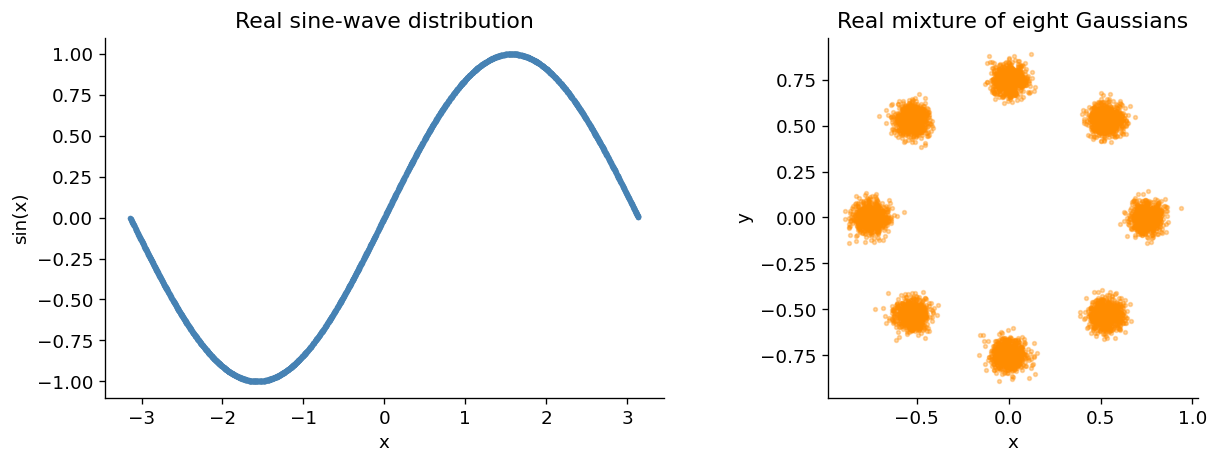

Sine training shape: (6000, 2)
Gaussian mixture training shape: (6000, 2)


In [3]:
def generate_sine_data(n_samples=6000, seed=SEED):
    """Return normalised training points and sine-wave points in original units."""
    rng = np.random.default_rng(seed)

    x = rng.uniform(-np.pi, np.pi, n_samples)
    y = np.sin(x)

    original = np.column_stack((x, y)).astype(np.float32)

    # I scale x so that both coordinates have similar ranges.
    scaled = np.column_stack((x / np.pi, y)).astype(np.float32)

    return scaled, original


def generate_gaussian_mixture(
    n_samples=6000,
    n_clusters=8,
    radius=0.75,
    cluster_std=0.045,
    seed=SEED
):
    """Create an equally weighted mixture of Gaussian clusters on a circle."""
    rng = np.random.default_rng(seed)

    angles = np.linspace(0, 2 * np.pi, n_clusters, endpoint=False)
    centres = radius * np.column_stack((np.cos(angles), np.sin(angles)))

    cluster_labels = rng.integers(0, n_clusters, size=n_samples)

    points = centres[cluster_labels] + rng.normal(
        loc=0,
        scale=cluster_std,
        size=(n_samples, 2)
    )

    return points.astype(np.float32), centres.astype(np.float32)


sine_train, sine_original = generate_sine_data()
mixture_train, cluster_centres = generate_gaussian_mixture()

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

axes[0].scatter(
    sine_original[:, 0], sine_original[:, 1],
    s=5, alpha=0.4, color="steelblue"
)
axes[0].set(
    title="Real sine-wave distribution",
    xlabel="x", ylabel="sin(x)"
)

axes[1].scatter(
    mixture_train[:, 0], mixture_train[:, 1],
    s=5, alpha=0.35, color="darkorange"
)
axes[1].set(
    title="Real mixture of eight Gaussians",
    xlabel="x", ylabel="y"
)
axes[1].set_aspect("equal")

plt.tight_layout()
plt.show()

print("Sine training shape:", sine_train.shape)
print("Gaussian mixture training shape:", mixture_train.shape)

In [4]:
class Generator(nn.Module):
    """Map random latent vectors to generated 2D points."""

    def __init__(self, latent_dim=16, hidden_dim=128, depth=2):
        super().__init__()

        layers = []
        input_dim = latent_dim

        for _ in range(depth):
            layers.extend([
                nn.Linear(input_dim, hidden_dim),
                nn.LeakyReLU(0.2)
            ])
            input_dim = hidden_dim

        # I use a linear output because coordinates are continuous values.
        layers.append(nn.Linear(hidden_dim, 2))

        self.network = nn.Sequential(*layers)

    def forward(self, noise):
        return self.network(noise)


class Discriminator(nn.Module):
    """Return a real-versus-generated logit for each 2D point."""

    def __init__(self, hidden_dim=128, depth=2):
        super().__init__()

        layers = []
        input_dim = 2

        for _ in range(depth):
            layers.extend([
                nn.Linear(input_dim, hidden_dim),
                nn.LeakyReLU(0.2)
            ])
            input_dim = hidden_dim

        # BCEWithLogitsLoss applies the sigmoid operation internally.
        layers.append(nn.Linear(hidden_dim, 1))

        self.network = nn.Sequential(*layers)

    def forward(self, points):
        return self.network(points)


def initialise_weights(module):
    """Initialise linear layers consistently across experiments."""
    if isinstance(module, nn.Linear):
        nn.init.xavier_uniform_(module.weight)
        nn.init.zeros_(module.bias)


def generate_samples(generator, n_samples=3000, latent_dim=16, seed=123):
    """Generate reproducible samples without changing training gradients."""
    rng = torch.Generator(device="cpu")
    rng.manual_seed(seed)

    noise = torch.randn(n_samples, latent_dim, generator=rng).to(device)

    was_training = generator.training
    generator.eval()

    with torch.no_grad():
        samples = generator(noise).cpu().numpy()

    generator.train(was_training)
    return samples

In [5]:
def train_gan(
    data,
    experiment_name,
    depth=2,
    epochs=300,
    batch_size=256,
    latent_dim=16,
    learning_rate=0.0002,
    seed=SEED
):
    """Train a GAN and return its models, epoch losses and sample snapshots."""
    set_seed(seed)

    tensor_data = torch.as_tensor(data, dtype=torch.float32)

    loader_rng = torch.Generator().manual_seed(seed)

    loader = DataLoader(
        TensorDataset(tensor_data),
        batch_size=batch_size,
        shuffle=True,
        drop_last=False,
        generator=loader_rng
    )

    generator = Generator(latent_dim=latent_dim, depth=depth).to(device)
    discriminator = Discriminator(depth=depth).to(device)

    generator.apply(initialise_weights)
    discriminator.apply(initialise_weights)

    g_optimizer = torch.optim.Adam(
        generator.parameters(),
        lr=learning_rate,
        betas=(0.5, 0.999)
    )
    d_optimizer = torch.optim.Adam(
        discriminator.parameters(),
        lr=learning_rate,
        betas=(0.5, 0.999)
    )

    criterion = nn.BCEWithLogitsLoss()

    history = []
    snapshots = {}
    snapshot_epochs = {1, epochs // 3, (2 * epochs) // 3, epochs}

    for epoch in range(1, epochs + 1):
        generator.train()
        discriminator.train()

        total_g_loss = 0.0
        total_d_loss = 0.0
        total_records = 0

        for (real_points,) in loader:
            real_points = real_points.to(device)
            current_batch = real_points.size(0)

            real_targets = torch.ones(current_batch, 1, device=device)
            fake_targets = torch.zeros(current_batch, 1, device=device)

            # I first update the discriminator using real and generated points.
            d_optimizer.zero_grad(set_to_none=True)

            noise = torch.randn(current_batch, latent_dim, device=device)
            fake_points = generator(noise)

            real_loss = criterion(
                discriminator(real_points), real_targets
            )
            fake_loss = criterion(
                discriminator(fake_points.detach()), fake_targets
            )

            d_loss = 0.5 * (real_loss + fake_loss)
            d_loss.backward()
            d_optimizer.step()

            # I freeze discriminator weights during the generator update.
            for parameter in discriminator.parameters():
                parameter.requires_grad_(False)

            g_optimizer.zero_grad(set_to_none=True)

            noise = torch.randn(current_batch, latent_dim, device=device)
            generated_points = generator(noise)

            g_loss = criterion(
                discriminator(generated_points), real_targets
            )

            g_loss.backward()
            g_optimizer.step()

            for parameter in discriminator.parameters():
                parameter.requires_grad_(True)

            total_d_loss += d_loss.item() * current_batch
            total_g_loss += g_loss.item() * current_batch
            total_records += current_batch

        history.append({
            "epoch": epoch,
            "generator_loss": total_g_loss / total_records,
            "discriminator_loss": total_d_loss / total_records
        })

        if epoch in snapshot_epochs:
            snapshots[epoch] = generate_samples(
                generator, latent_dim=latent_dim
            )

        if epoch == 1 or epoch % 50 == 0:
            print(
                f"{experiment_name} | Epoch {epoch:3d}/{epochs} | "
                f"D loss: {history[-1]['discriminator_loss']:.4f} | "
                f"G loss: {history[-1]['generator_loss']:.4f}"
            )

    return {
        "generator": generator,
        "discriminator": discriminator,
        "history": pd.DataFrame(history),
        "snapshots": snapshots,
        "settings": {
            "depth": depth,
            "epochs": epochs,
            "batch_size": batch_size,
            "latent_dim": latent_dim,
            "learning_rate": learning_rate,
            "seed": seed
        }
    }

In [6]:
EPOCHS = 300

# I train the baseline GAN on the sine wave.
sine_result = train_gan(
    sine_train,
    experiment_name="Sine baseline",
    depth=2,
    epochs=EPOCHS
)

# I train the same baseline architecture on the new distribution.
mixture_baseline = train_gan(
    mixture_train,
    experiment_name="Mixture baseline",
    depth=2,
    epochs=EPOCHS
)

# I add one hidden layer to both networks for the modified experiment.
mixture_modified = train_gan(
    mixture_train,
    experiment_name="Mixture modified",
    depth=3,
    epochs=EPOCHS
)

experiments = {
    "Sine baseline": sine_result,
    "Mixture baseline": mixture_baseline,
    "Mixture modified": mixture_modified
}

Sine baseline | Epoch   1/300 | D loss: 0.6882 | G loss: 0.6870
Sine baseline | Epoch  50/300 | D loss: 0.6482 | G loss: 0.7694
Sine baseline | Epoch 100/300 | D loss: 0.6659 | G loss: 0.7638
Sine baseline | Epoch 150/300 | D loss: 0.6586 | G loss: 0.7617
Sine baseline | Epoch 200/300 | D loss: 0.6819 | G loss: 0.7593
Sine baseline | Epoch 250/300 | D loss: 0.6857 | G loss: 0.7087
Sine baseline | Epoch 300/300 | D loss: 0.6883 | G loss: 0.7003
Mixture baseline | Epoch   1/300 | D loss: 0.6913 | G loss: 0.6875
Mixture baseline | Epoch  50/300 | D loss: 0.6787 | G loss: 0.7152
Mixture baseline | Epoch 100/300 | D loss: 0.6017 | G loss: 0.9026
Mixture baseline | Epoch 150/300 | D loss: 0.6966 | G loss: 0.6916
Mixture baseline | Epoch 200/300 | D loss: 0.4704 | G loss: 1.1576
Mixture baseline | Epoch 250/300 | D loss: 0.6970 | G loss: 0.7486
Mixture baseline | Epoch 300/300 | D loss: 0.6261 | G loss: 0.7976
Mixture modified | Epoch   1/300 | D loss: 0.6850 | G loss: 0.6855
Mixture modified

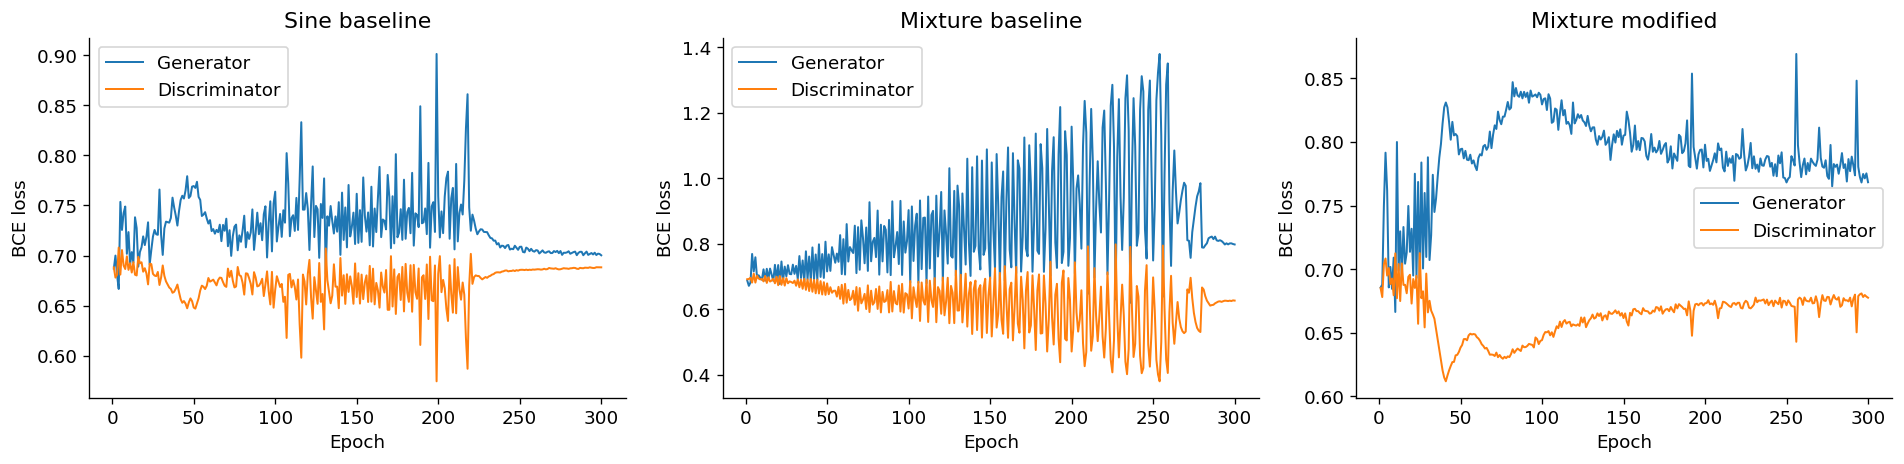

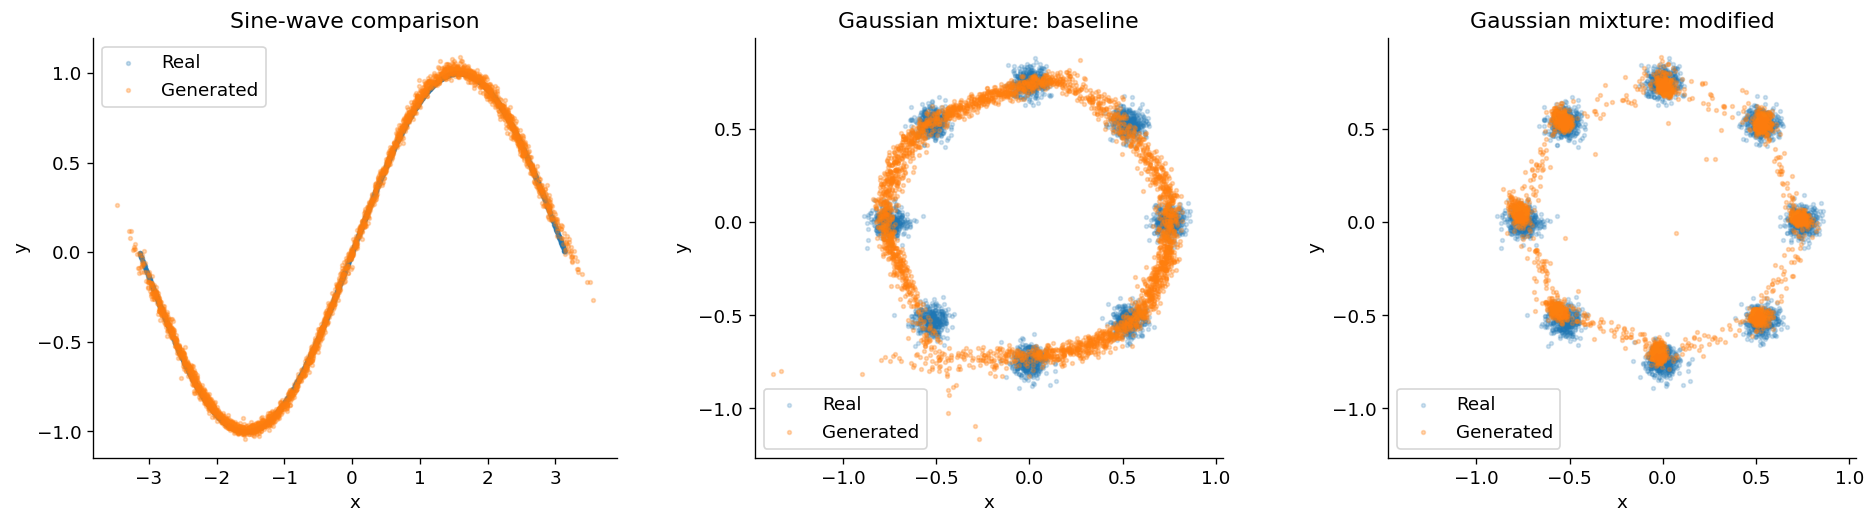

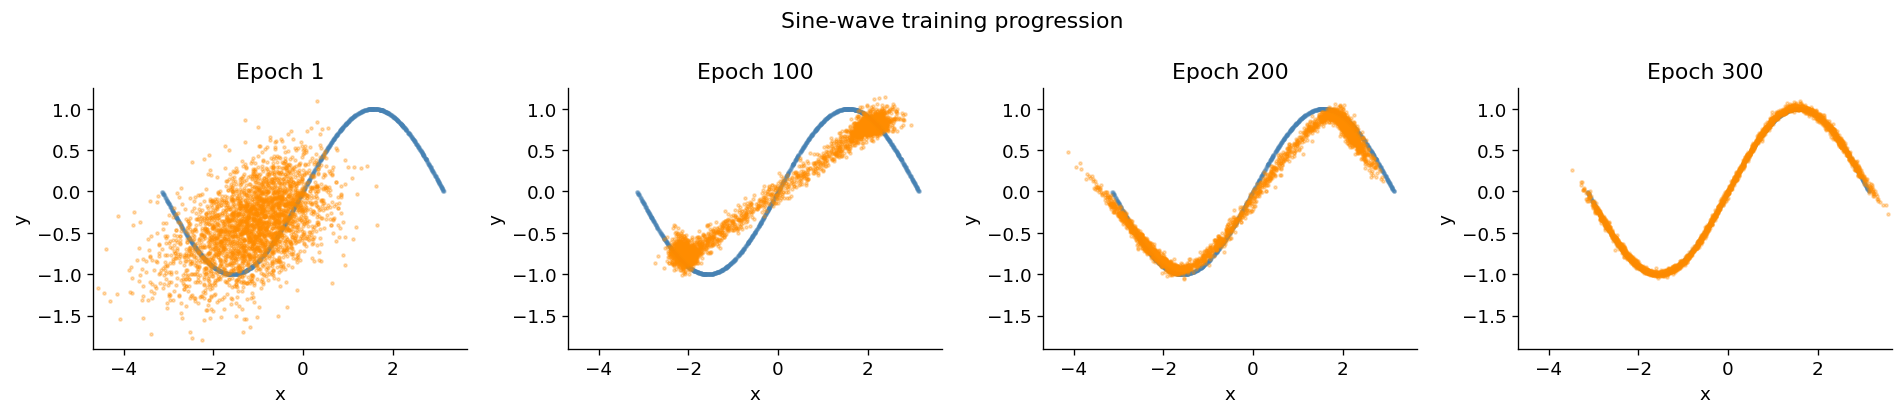

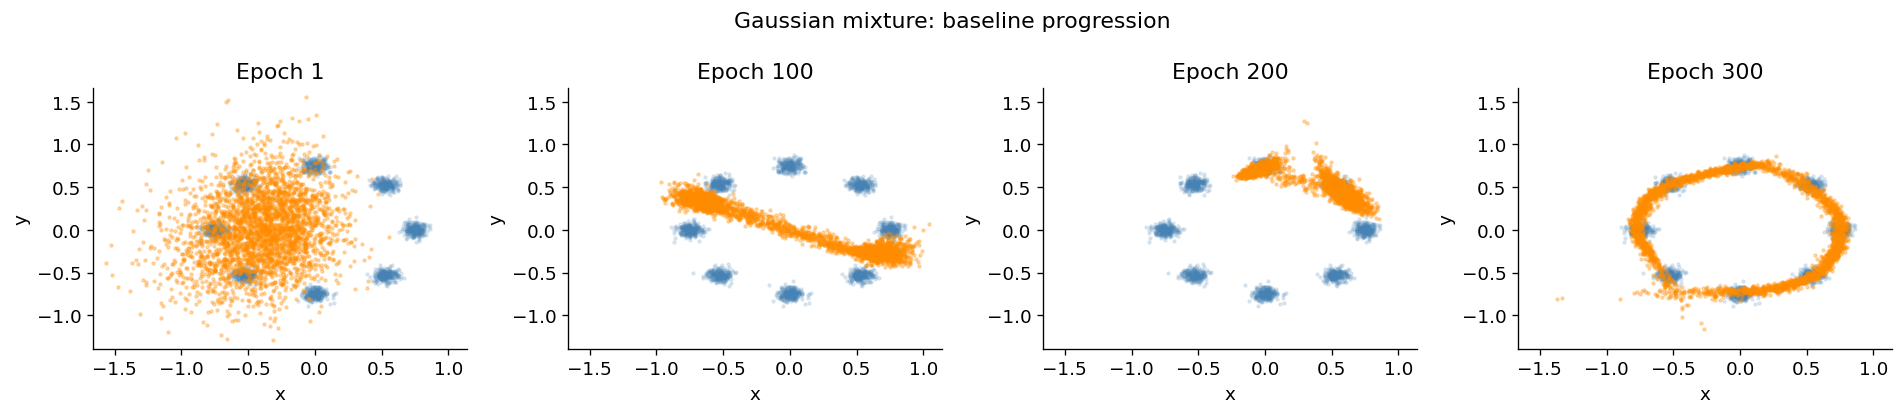

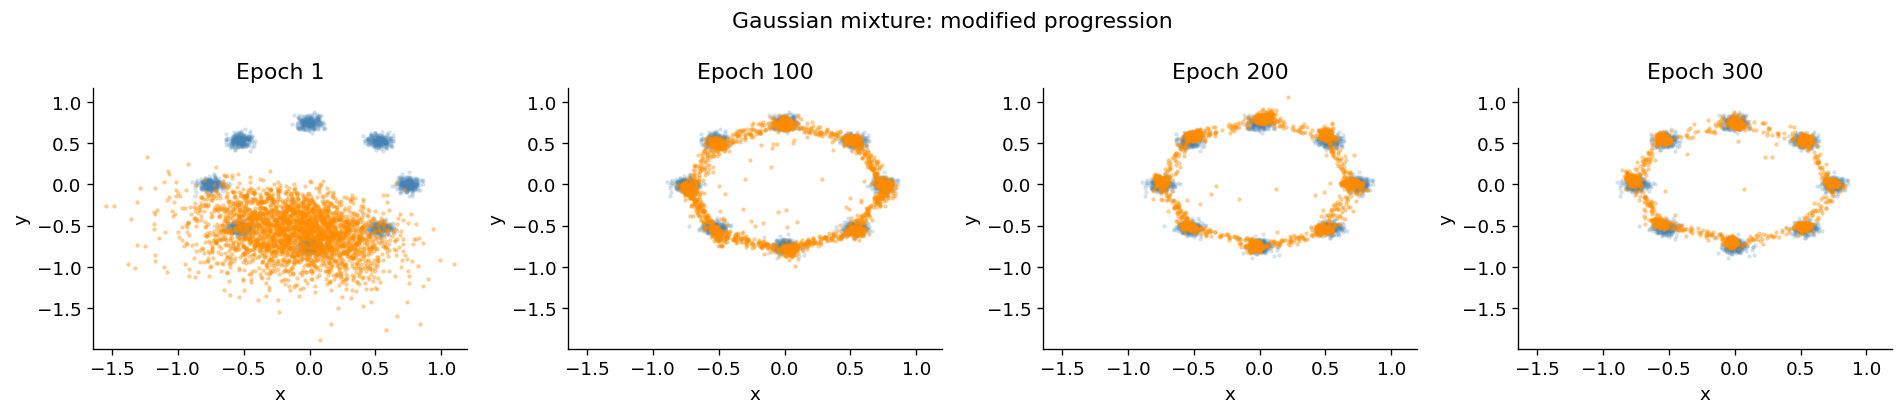

In [7]:
# I compare the loss histories for all three experiments.
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

for ax, (name, result) in zip(axes, experiments.items()):
    history = result["history"]

    ax.plot(
        history["epoch"], history["generator_loss"],
        label="Generator", linewidth=1.2
    )
    ax.plot(
        history["epoch"], history["discriminator_loss"],
        label="Discriminator", linewidth=1.2
    )
    ax.set(title=name, xlabel="Epoch", ylabel="BCE loss")
    ax.legend()

plt.tight_layout()
plt.show()


sine_fake = generate_samples(sine_result["generator"])
baseline_fake = generate_samples(mixture_baseline["generator"])
modified_fake = generate_samples(mixture_modified["generator"])

# I restore the sine-wave x coordinate to its original units.
sine_fake_original = sine_fake.copy()
sine_fake_original[:, 0] *= np.pi

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

axes[0].scatter(
    sine_original[:3000, 0], sine_original[:3000, 1],
    s=5, alpha=0.25, label="Real"
)
axes[0].scatter(
    sine_fake_original[:, 0], sine_fake_original[:, 1],
    s=5, alpha=0.3, label="Generated"
)
axes[0].set(title="Sine-wave comparison", xlabel="x", ylabel="y")
axes[0].legend()

# I use shared limits so the architecture comparison is fair.
combined = np.vstack((mixture_train, baseline_fake, modified_fake))
lower = combined.min(axis=0) - 0.1
upper = combined.max(axis=0) + 0.1

for ax, fake, title in [
    (axes[1], baseline_fake, "Gaussian mixture: baseline"),
    (axes[2], modified_fake, "Gaussian mixture: modified")
]:
    ax.scatter(
        mixture_train[:3000, 0], mixture_train[:3000, 1],
        s=5, alpha=0.2, label="Real"
    )
    ax.scatter(
        fake[:, 0], fake[:, 1],
        s=5, alpha=0.3, label="Generated"
    )
    ax.set(
        title=title, xlabel="x", ylabel="y",
        xlim=(lower[0], upper[0]),
        ylim=(lower[1], upper[1])
    )
    ax.set_aspect("equal", adjustable="box")
    ax.legend()

plt.tight_layout()
plt.show()


def plot_progression(result, title, restore_sine=False):
    """Show fixed-noise samples at selected training epochs."""
    snapshots = result["snapshots"]
    fig, axes = plt.subplots(
        1, len(snapshots), figsize=(4 * len(snapshots), 3.5),
        squeeze=False
    )

    real = sine_original if restore_sine else mixture_train
    plotted_samples = []

    for epoch, samples in snapshots.items():
        samples = samples.copy()
        if restore_sine:
            samples[:, 0] *= np.pi
        plotted_samples.append((epoch, samples))

    all_points = np.vstack([real] + [s for _, s in plotted_samples])
    low = all_points.min(axis=0) - 0.1
    high = all_points.max(axis=0) + 0.1

    for ax, (epoch, samples) in zip(axes.ravel(), plotted_samples):
        ax.scatter(
            real[:2000, 0], real[:2000, 1],
            s=3, alpha=0.15, color="steelblue"
        )
        ax.scatter(
            samples[:, 0], samples[:, 1],
            s=3, alpha=0.3, color="darkorange"
        )
        ax.set(
            title=f"Epoch {epoch}", xlabel="x", ylabel="y",
            xlim=(low[0], high[0]), ylim=(low[1], high[1])
        )

    fig.suptitle(title)
    plt.tight_layout()
    plt.show()


plot_progression(sine_result, "Sine-wave training progression", True)
plot_progression(mixture_baseline, "Gaussian mixture: baseline progression")
plot_progression(mixture_modified, "Gaussian mixture: modified progression")

Gaussian-mixture evaluation:


,Modes covered (out of 8),Points near a mode (%),Mean distance to nearest centre,Cluster balance distance
Real reference,8.0,98.6667,0.0565,0.0108
Baseline GAN,8.0,44.9000,0.1527,0.1367
Modified GAN,8.0,91.0333,0.0638,0.0292



Mean absolute sine-curve error: 0.0219
Generated x values inside the real range: 98.57%
x-range bins covered: 20/20


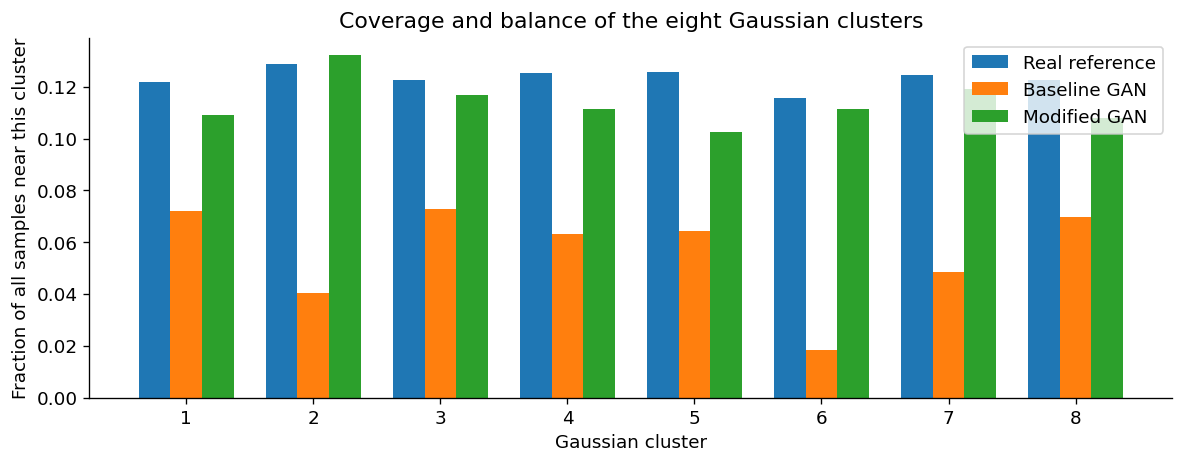

In [8]:
def evaluate_mixture(
    samples,
    centres,
    cluster_std=0.045,
    minimum_cluster_fraction=0.01
):
    """Measure proximity to real modes, mode coverage and cluster balance."""
    distances = np.linalg.norm(
        samples[:, None, :] - centres[None, :, :],
        axis=2
    )

    nearest_cluster = distances.argmin(axis=1)
    nearest_distance = distances.min(axis=1)

    # I treat points within three cluster standard deviations as nearby.
    nearby = nearest_distance <= 3 * cluster_std

    counts = np.bincount(
        nearest_cluster[nearby],
        minlength=len(centres)
    )

    minimum_count = int(np.ceil(minimum_cluster_fraction * len(samples)))
    modes_covered = int((counts >= minimum_count).sum())

    if counts.sum() > 0:
        proportions = counts / counts.sum()
        uniform = np.full(len(centres), 1 / len(centres))

        # Total variation is zero when the nearby points are equally balanced.
        balance_distance = 0.5 * np.abs(proportions - uniform).sum()
    else:
        balance_distance = np.nan

    metrics = {
        "Modes covered (out of 8)": modes_covered,
        "Points near a mode (%)": 100 * nearby.mean(),
        "Mean distance to nearest centre": nearest_distance.mean(),
        "Cluster balance distance": balance_distance
    }

    return metrics, counts


real_metrics, real_counts = evaluate_mixture(
    mixture_train, cluster_centres
)
baseline_metrics, baseline_counts = evaluate_mixture(
    baseline_fake, cluster_centres
)
modified_metrics, modified_counts = evaluate_mixture(
    modified_fake, cluster_centres
)

comparison = pd.DataFrame({
    "Real reference": real_metrics,
    "Baseline GAN": baseline_metrics,
    "Modified GAN": modified_metrics
}).T

print("Gaussian-mixture evaluation:")
display(comparison.round(4))

# I check closeness to the sine curve and coverage of the valid x range.
x_generated = sine_fake_original[:, 0]
y_generated = sine_fake_original[:, 1]

valid_x = (x_generated >= -np.pi) & (x_generated <= np.pi)
sine_error = np.abs(y_generated - np.sin(x_generated)).mean()

bins = np.linspace(-np.pi, np.pi, 21)
bin_counts, _ = np.histogram(x_generated[valid_x], bins=bins)

minimum_bin_count = int(np.ceil(0.01 * len(x_generated)))
covered_bins = (bin_counts >= minimum_bin_count).sum()

print(f"\nMean absolute sine-curve error: {sine_error:.4f}")
print(f"Generated x values inside the real range: {100 * valid_x.mean():.2f}%")
print(f"x-range bins covered: {covered_bins}/20")

# I show whether some Gaussian clusters are missing or overrepresented.
cluster_positions = np.arange(1, 9)
width = 0.25

plt.figure(figsize=(10, 4))
plt.bar(
    cluster_positions - width,
    real_counts / len(mixture_train),
    width, label="Real reference"
)
plt.bar(
    cluster_positions,
    baseline_counts / len(baseline_fake),
    width, label="Baseline GAN"
)
plt.bar(
    cluster_positions + width,
    modified_counts / len(modified_fake),
    width, label="Modified GAN"
)

plt.xticks(cluster_positions)
plt.xlabel("Gaussian cluster")
plt.ylabel("Fraction of all samples near this cluster")
plt.title("Coverage and balance of the eight Gaussian clusters")
plt.legend()
plt.tight_layout()
plt.show()

Device: cuda


100%|██████████| 54.9M/54.9M [00:53<00:00, 1.02MB/s]



Split sizes:


,Split,Images
0,train,97477
1,val,10832
2,test,1000


Original training image shape: (97477, 28, 28)
Model input shape: (1, 64, 64)


,train,val,test
choroidal neovascularization,33484,3721,250
diabetic macular edema,10213,1135,250
drusen,7754,862,250
normal,46026,5114,250


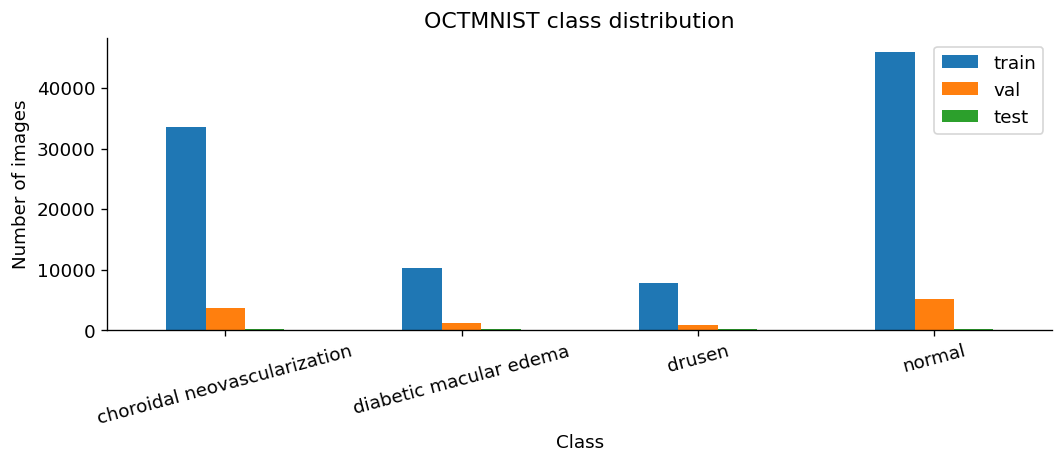

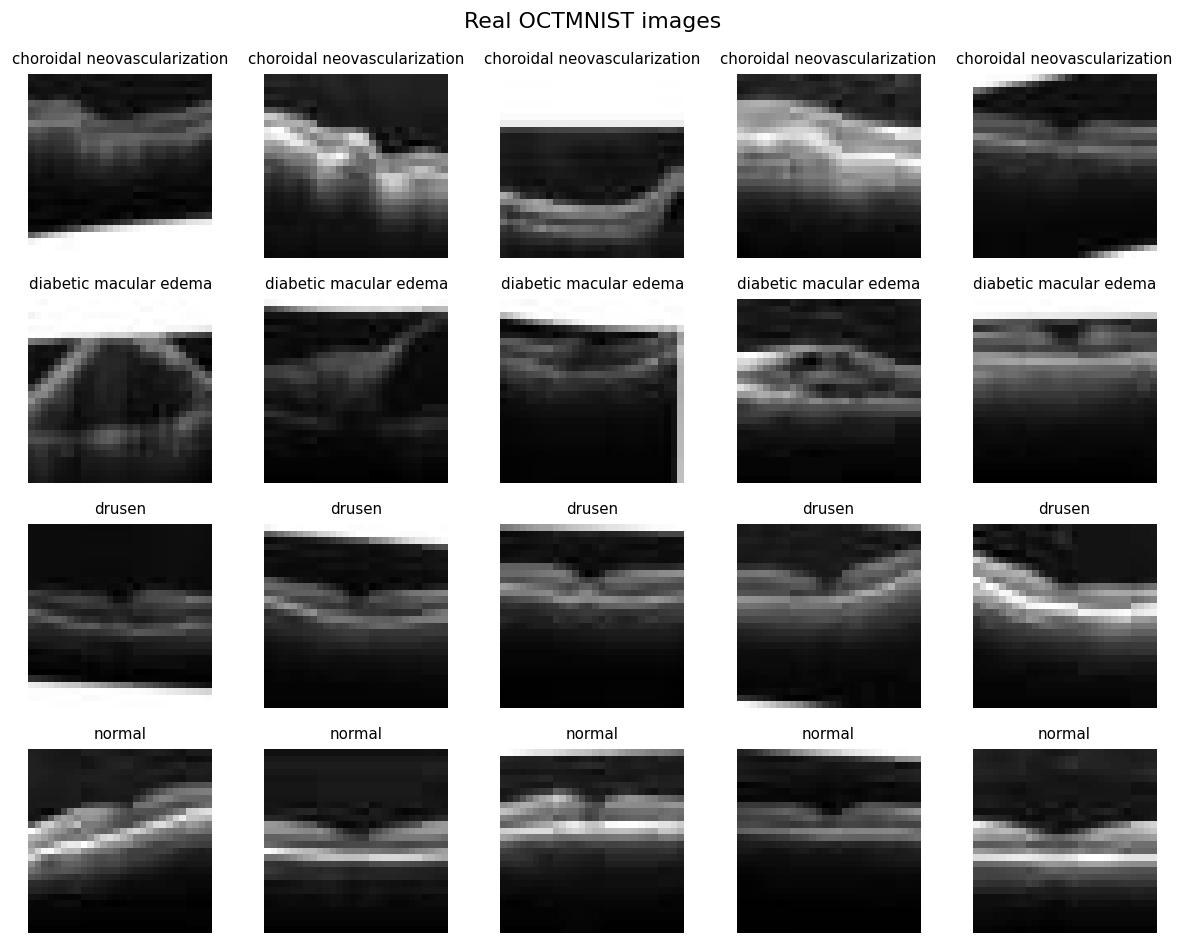

In [9]:
%pip -q install medmnist torchmetrics torch-fidelity

import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn

from torch.utils.data import DataLoader, Subset
from torchvision import transforms
from torchvision.utils import make_grid
from medmnist import OCTMNIST, INFO
from torchmetrics.image.fid import FrechetInceptionDistance

SEED = 42
BATCH_SIZE = 128
LATENT_DIM = 100

def set_seed(seed):
    """Set random seeds for reproducible experiments."""
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

set_seed(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

# I resize images for the DCGAN and match the Tanh output range.
transform = transforms.Compose([
    transforms.Resize((64, 64)),
    transforms.ToTensor(),
    transforms.Normalize((0.5,), (0.5,))
])

datasets = {
    split: OCTMNIST(
        split=split, download=True, size=28, transform=transform
    )
    for split in ["train", "val", "test"]
}

train_data = datasets["train"]
test_data = datasets["test"]
label_names = INFO["octmnist"]["label"]
class_ids = sorted(int(k) for k in label_names)

print("\nSplit sizes:")
display(pd.DataFrame({
    "Split": list(datasets),
    "Images": [len(dataset) for dataset in datasets.values()]
}))

print("Original training image shape:", train_data.imgs.shape)
print("Model input shape:", tuple(train_data[0][0].shape))

# I examine class counts across the official splits.
class_counts = pd.DataFrame({
    split: [
        int((dataset.labels.reshape(-1) == class_id).sum())
        for class_id in class_ids
    ]
    for split, dataset in datasets.items()
}, index=[label_names[str(i)] for i in class_ids])

display(class_counts)

class_counts.plot.bar(figsize=(9, 4), rot=15)
plt.title("OCTMNIST class distribution")
plt.xlabel("Class")
plt.ylabel("Number of images")
plt.tight_layout()
plt.show()

# I display examples from every training class.
rng = np.random.default_rng(SEED)
labels = train_data.labels.reshape(-1)

fig, axes = plt.subplots(len(class_ids), 5, figsize=(10, 8))

for row, class_id in enumerate(class_ids):
    indices = rng.choice(
        np.flatnonzero(labels == class_id), size=5, replace=False
    )
    for col, index in enumerate(indices):
        axes[row, col].imshow(train_data.imgs[index], cmap="gray")
        axes[row, col].set_title(label_names[str(class_id)], fontsize=9)
        axes[row, col].axis("off")

fig.suptitle("Real OCTMNIST images")
plt.tight_layout()
plt.show()

train_loader = DataLoader(
    train_data,
    batch_size=BATCH_SIZE,
    shuffle=True,
    drop_last=True,
    num_workers=2,
    pin_memory=(device.type == "cuda"),
    generator=torch.Generator().manual_seed(SEED)
)

Epoch 01/30 | Generator: 0.0571 | Discriminator: 0.0023
Epoch 02/30 | Generator: 0.0000 | Discriminator: 0.0000
Epoch 03/30 | Generator: 0.0000 | Discriminator: 0.0000
Epoch 04/30 | Generator: 0.0000 | Discriminator: 0.0000
Epoch 05/30 | Generator: 0.0000 | Discriminator: 0.0000
Epoch 06/30 | Generator: 0.0000 | Discriminator: 0.0000
Epoch 07/30 | Generator: 0.0000 | Discriminator: 0.0000
Epoch 08/30 | Generator: 0.0000 | Discriminator: 0.0000
Epoch 09/30 | Generator: 0.0000 | Discriminator: 0.0000
Epoch 10/30 | Generator: 0.0000 | Discriminator: 0.0000
Epoch 11/30 | Generator: 0.0000 | Discriminator: 0.0000
Epoch 12/30 | Generator: 0.0000 | Discriminator: 0.0000
Epoch 13/30 | Generator: 0.0000 | Discriminator: 0.0000
Epoch 14/30 | Generator: 0.0000 | Discriminator: 0.0000
Epoch 15/30 | Generator: 0.0000 | Discriminator: 0.0000
Epoch 16/30 | Generator: 0.0000 | Discriminator: 0.0000
Epoch 17/30 | Generator: 0.0000 | Discriminator: 0.0000
Epoch 18/30 | Generator: 0.0000 | Discriminator:

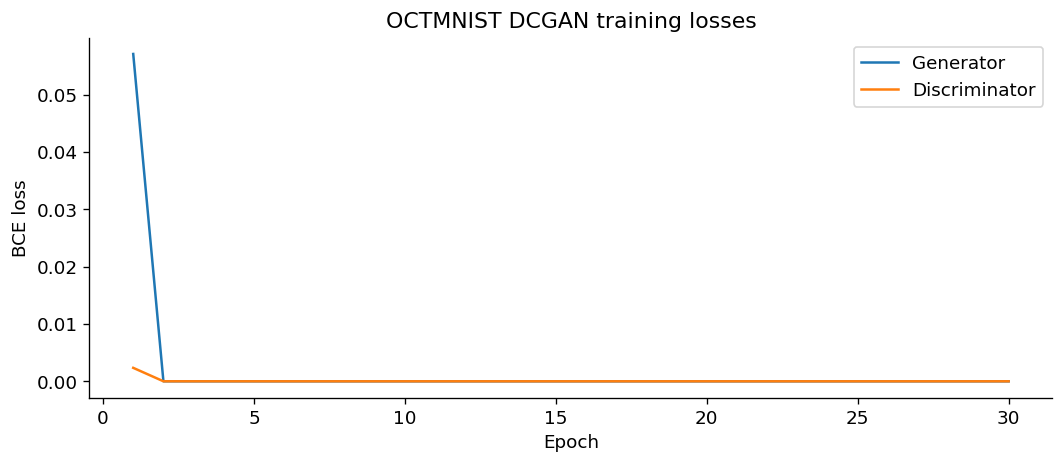

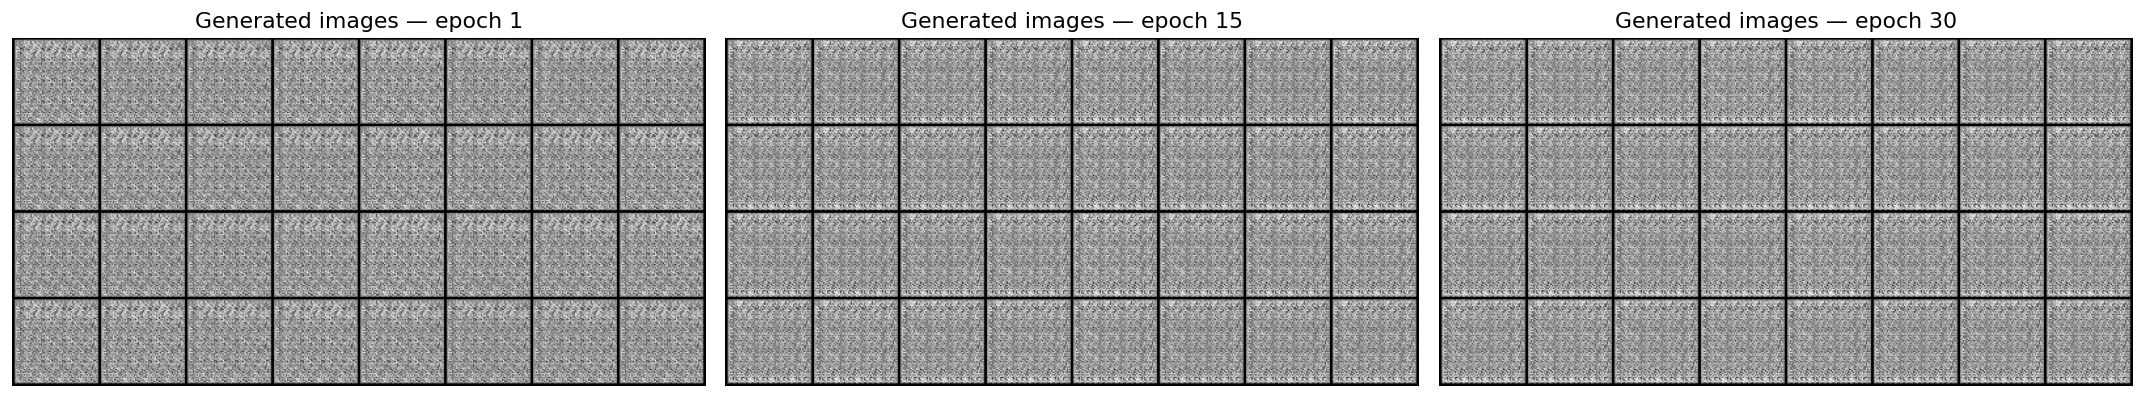

In [10]:
EPOCHS = 30
LEARNING_RATE = 0.0002
BASE = 32

class Generator(nn.Module):
    """Generate grayscale 64 × 64 images from latent noise."""
    def __init__(self):
        super().__init__()
        self.network = nn.Sequential(
            nn.ConvTranspose2d(LATENT_DIM, BASE * 8, 4, 1, 0, bias=False),
            nn.BatchNorm2d(BASE * 8),
            nn.ReLU(True),

            nn.ConvTranspose2d(BASE * 8, BASE * 4, 4, 2, 1, bias=False),
            nn.BatchNorm2d(BASE * 4),
            nn.ReLU(True),

            nn.ConvTranspose2d(BASE * 4, BASE * 2, 4, 2, 1, bias=False),
            nn.BatchNorm2d(BASE * 2),
            nn.ReLU(True),

            nn.ConvTranspose2d(BASE * 2, BASE, 4, 2, 1, bias=False),
            nn.BatchNorm2d(BASE),
            nn.ReLU(True),

            nn.ConvTranspose2d(BASE, 1, 4, 2, 1, bias=False),
            nn.Tanh()
        )

    def forward(self, noise):
        return self.network(noise)


class Discriminator(nn.Module):
    """Return one real-versus-fake logit per image."""
    def __init__(self):
        super().__init__()
        self.network = nn.Sequential(
            nn.Conv2d(1, BASE, 4, 2, 1, bias=False),
            nn.LeakyReLU(0.2, inplace=True),

            nn.Conv2d(BASE, BASE * 2, 4, 2, 1, bias=False),
            nn.BatchNorm2d(BASE * 2),
            nn.LeakyReLU(0.2, inplace=True),

            nn.Conv2d(BASE * 2, BASE * 4, 4, 2, 1, bias=False),
            nn.BatchNorm2d(BASE * 4),
            nn.LeakyReLU(0.2, inplace=True),

            nn.Conv2d(BASE * 4, BASE * 8, 4, 2, 1, bias=False),
            nn.BatchNorm2d(BASE * 8),
            nn.LeakyReLU(0.2, inplace=True),

            nn.Conv2d(BASE * 8, 1, 4, 1, 0, bias=False)
        )

    def forward(self, images):
        return self.network(images).flatten()


def initialise_weights(module):
    """Apply DCGAN weight initialisation."""
    if isinstance(module, (nn.Conv2d, nn.ConvTranspose2d)):
        nn.init.normal_(module.weight, 0.0, 0.02)
    elif isinstance(module, nn.BatchNorm2d):
        nn.init.normal_(module.weight, 1.0, 0.02)
        nn.init.zeros_(module.bias)


@torch.no_grad()
def generate_images(model, noise):
    """Generate samples without updating batch-normalisation statistics."""
    previous_mode = model.training
    model.eval()
    images = model(noise).cpu()
    model.train(previous_mode)
    return images


def train_dcgan(generator, discriminator, loader, epochs):
    """Train the GAN and record losses and fixed-noise image grids."""
    criterion = nn.BCEWithLogitsLoss()

    g_optimizer = torch.optim.Adam(
        generator.parameters(), lr=LEARNING_RATE, betas=(0.5, 0.999)
    )
    d_optimizer = torch.optim.Adam(
        discriminator.parameters(), lr=LEARNING_RATE, betas=(0.5, 0.999)
    )

    fixed_noise = torch.randn(32, LATENT_DIM, 1, 1, device=device)
    snapshot_epochs = {1, max(1, epochs // 2), epochs}
    history, snapshots = [], {}

    for epoch in range(1, epochs + 1):
        generator.train()
        discriminator.train()
        g_total, d_total, count = 0.0, 0.0, 0

        for real_images, _ in loader:
            real_images = real_images.to(device, non_blocking=True)
            size = real_images.size(0)

            real_targets = torch.ones(size, device=device)
            fake_targets = torch.zeros(size, device=device)

            # I train the discriminator on real and generated images.
            d_optimizer.zero_grad(set_to_none=True)
            noise = torch.randn(size, LATENT_DIM, 1, 1, device=device)
            fake_images = generator(noise)

            d_loss = 0.5 * (
                criterion(discriminator(real_images), real_targets)
                + criterion(
                    discriminator(fake_images.detach()), fake_targets
                )
            )
            d_loss.backward()
            d_optimizer.step()

            # I freeze the discriminator while updating the generator.
            discriminator.eval()
            for parameter in discriminator.parameters():
                parameter.requires_grad_(False)

            g_optimizer.zero_grad(set_to_none=True)
            g_loss = criterion(discriminator(fake_images), real_targets)
            g_loss.backward()
            g_optimizer.step()

            for parameter in discriminator.parameters():
                parameter.requires_grad_(True)
            discriminator.train()

            g_total += g_loss.item() * size
            d_total += d_loss.item() * size
            count += size

        history.append({
            "epoch": epoch,
            "generator_loss": g_total / count,
            "discriminator_loss": d_total / count
        })

        if epoch in snapshot_epochs:
            snapshots[epoch] = generate_images(generator, fixed_noise)

        print(
            f"Epoch {epoch:02d}/{epochs} | "
            f"Generator: {g_total / count:.4f} | "
            f"Discriminator: {d_total / count:.4f}"
        )

    return pd.DataFrame(history), snapshots


set_seed(SEED)

generator = Generator().to(device)
discriminator = Discriminator().to(device)
generator.apply(initialise_weights)
discriminator.apply(initialise_weights)

history, snapshots = train_dcgan(
    generator, discriminator, train_loader, EPOCHS
)

plt.figure(figsize=(9, 4))
plt.plot(history["epoch"], history["generator_loss"], label="Generator")
plt.plot(history["epoch"], history["discriminator_loss"], label="Discriminator")
plt.title("OCTMNIST DCGAN training losses")
plt.xlabel("Epoch")
plt.ylabel("BCE loss")
plt.legend()
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(
    1, len(snapshots), figsize=(6 * len(snapshots), 5), squeeze=False
)

for ax, (epoch, images) in zip(axes.ravel(), snapshots.items()):
    grid = make_grid(
        ((images + 1) / 2).clamp(0, 1), nrow=8, padding=2
    )
    ax.imshow(grid.permute(1, 2, 0).numpy())
    ax.set_title(f"Generated images — epoch {epoch}")
    ax.axis("off")

plt.tight_layout()
plt.show()

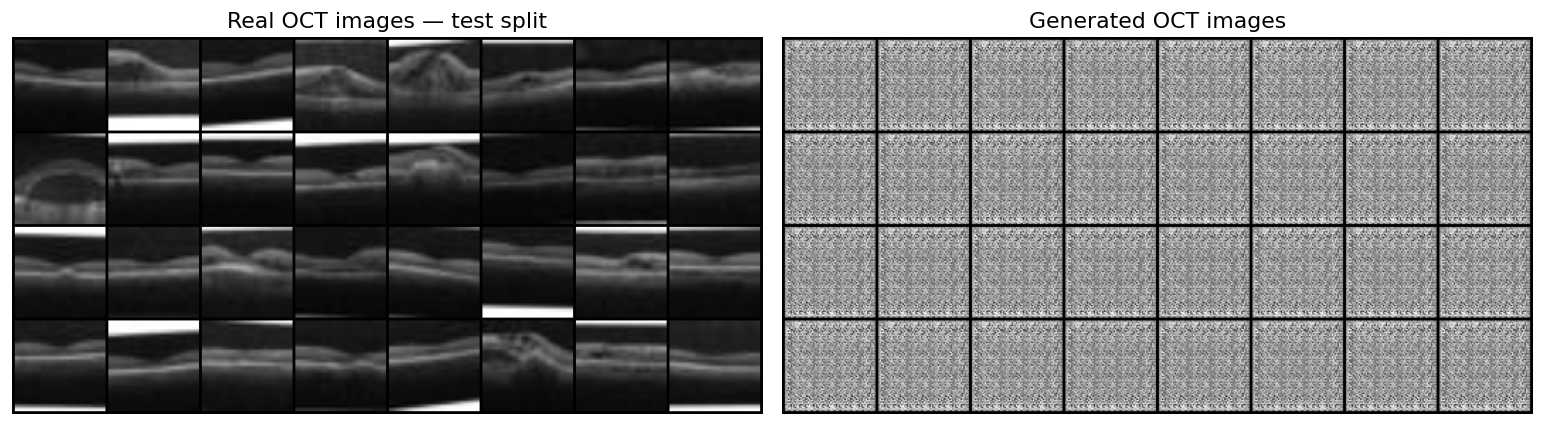

Calculating FID. Inception weights download on the first run.


Downloading: "https://github.com/toshas/torch-fidelity/releases/download/v0.2.0/weights-inception-2015-12-05-6726825d.pth" to /root/.cache/torch/hub/checkpoints/weights-inception-2015-12-05-6726825d.pth
100%|██████████| 91.2M/91.2M [00:00<00:00, 241MB/s]


,Model,Epochs,Image dimensions,Real images,Generated images,Evaluation split,FID feature dimensions,FID
0,Unconditional DCGAN,30,64 × 64,1000,1000,Test,2048,441.5002


In [11]:
N_EVAL = min(2000, len(test_data))
EVAL_BATCH_SIZE = 64

# I reserve held-out test images for the final comparison.
rng = np.random.default_rng(SEED)
test_indices = rng.choice(len(test_data), N_EVAL, replace=False)

evaluation_loader = DataLoader(
    Subset(test_data, test_indices.tolist()),
    batch_size=EVAL_BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=(device.type == "cuda")
)

real_examples = torch.stack([
    test_data[int(index)][0] for index in test_indices[:32]
])

noise_rng = torch.Generator().manual_seed(SEED + 100)
example_noise = torch.randn(
    32, LATENT_DIM, 1, 1, generator=noise_rng
).to(device)

fake_examples = generate_images(generator, example_noise)

fig, axes = plt.subplots(1, 2, figsize=(13, 6))

for ax, images, title in [
    (axes[0], real_examples, "Real OCT images — test split"),
    (axes[1], fake_examples, "Generated OCT images")
]:
    grid = make_grid(
        ((images + 1) / 2).clamp(0, 1), nrow=8, padding=2
    )
    ax.imshow(grid.permute(1, 2, 0).numpy())
    ax.set_title(title)
    ax.axis("off")

plt.tight_layout()
plt.show()


def prepare_for_fid(images):
    """Convert [-1, 1] grayscale images to three-channel [0, 1] images."""
    return ((images + 1) / 2).clamp(0, 1).repeat(1, 3, 1, 1)


@torch.no_grad()
def calculate_fid(model, loader):
    """Compare equal numbers of held-out real and generated images."""
    metric = FrechetInceptionDistance(
        feature=2048, normalize=True
    ).to(device)
    metric.set_dtype(torch.float64)

    previous_mode = model.training
    model.eval()
    noise_rng = torch.Generator().manual_seed(SEED + 200)
    image_count = 0

    for real_images, _ in loader:
        real_images = real_images.to(device, non_blocking=True)
        size = real_images.size(0)

        noise = torch.randn(
            size, LATENT_DIM, 1, 1, generator=noise_rng
        ).to(device)

        fake_images = model(noise)

        metric.update(prepare_for_fid(real_images), real=True)
        metric.update(prepare_for_fid(fake_images), real=False)
        image_count += size

    score = float(metric.compute().cpu())
    model.train(previous_mode)
    return score, image_count


print("Calculating FID. Inception weights download on the first run.")
fid_score, image_count = calculate_fid(generator, evaluation_loader)

results = pd.DataFrame([{
    "Model": "Unconditional DCGAN",
    "Epochs": EPOCHS,
    "Image dimensions": "64 × 64",
    "Real images": image_count,
    "Generated images": image_count,
    "Evaluation split": "Test",
    "FID feature dimensions": 2048,
    "FID": fid_score
}])

display(results.round(4))

Device: cuda
Using Colab cache for faster access to the 'network-intrusion-dataset' dataset.

CSV files found: 8
Reading: Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv
Reading: Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv
Reading: Friday-WorkingHours-Morning.pcap_ISCX.csv
Reading: Monday-WorkingHours.pcap_ISCX.csv
Reading: Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv
Reading: Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv
Reading: Tuesday-WorkingHours.pcap_ISCX.csv
Reading: Wednesday-workingHours.pcap_ISCX.csv

Daily file summary:


,Source,Rows
0,Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv,225745
1,Friday-WorkingHours-Afternoon-PortScan.pcap_IS...,286467
2,Friday-WorkingHours-Morning.pcap_ISCX.csv,191033
3,Monday-WorkingHours.pcap_ISCX.csv,529918
4,Thursday-WorkingHours-Afternoon-Infilteration....,288602
5,Thursday-WorkingHours-Morning-WebAttacks.pcap_...,170366
6,Tuesday-WorkingHours.pcap_ISCX.csv,445909
7,Wednesday-workingHours.pcap_ISCX.csv,692703



Combined class distribution:


,Count
Label,
BENIGN,2273097
DoS Hulk,231073
PortScan,158930
DDoS,128027
DoS GoldenEye,10293
FTP-Patator,7938
SSH-Patator,5897
DoS slowloris,5796
DoS Slowhttptest,5499


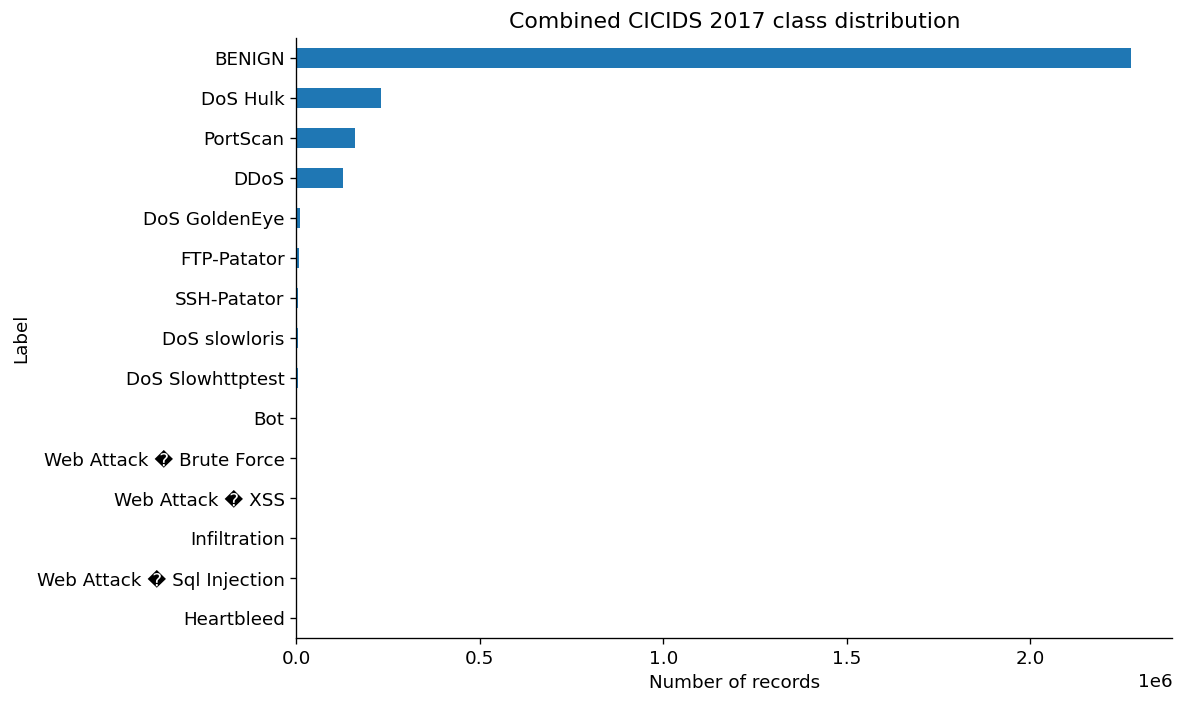


Wednesday records before duplicate removal: 692692
Feature count: 78
Missing numerical values: 2594
Exact duplicate records removed: 81948


,Count,Percentage
Label,,
BENIGN,417011,68.28
DoS Hulk,172849,28.30
DoS GoldenEye,10282,1.68
DoS slowloris,5374,0.88
DoS Slowhttptest,5228,0.86


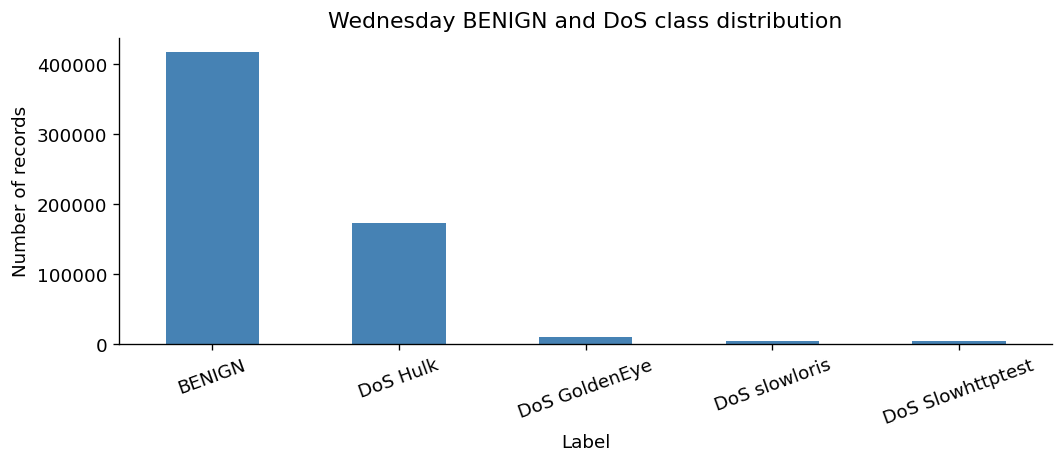


Training shape: (80000, 68)
Evaluation shape: (20000, 68)
Retained numerical features: 68

Class distribution in the modelling subset:


,Count
Label,
BENIGN,68279
DoS Hulk,28301
DoS GoldenEye,1684
DoS slowloris,880
DoS Slowhttptest,856



Training feature summary:


,count,mean,std,min,25%,50%,75%,max
Destination Port,80000.0,6.339106e+03,1.649855e+04,0.0,53.00,80.000,4.430000e+02,6.541700e+04
Flow Duration,80000.0,3.194982e+07,4.431753e+07,-1.0,1397.75,152673.000,8.494911e+07,1.200000e+08
Total Fwd Packets,80000.0,7.667000e+00,1.152700e+02,1.0,2.00,3.000,7.000000e+00,1.849400e+04
Total Backward Packets,80000.0,7.706000e+00,1.516360e+02,0.0,1.00,2.000,6.000000e+00,2.455300e+04
Total Length of Fwd Packets,80000.0,6.103840e+02,4.659608e+03,0.0,46.00,102.000,3.760000e+02,7.045360e+05
Total Length of Bwd Packets,80000.0,1.028938e+04,3.335429e+05,0.0,18.00,253.000,1.159500e+04,5.540000e+07
Fwd Packet Length Max,80000.0,2.611600e+02,6.113740e+02,0.0,31.00,52.000,3.510000e+02,1.898000e+04
Fwd Packet Length Min,80000.0,1.516500e+01,3.700000e+01,0.0,0.00,0.000,3.400000e+01,1.983000e+03
Fwd Packet Length Mean,80000.0,6.629000e+01,1.577260e+02,0.0,27.00,43.625,6.016700e+01,3.727704e+03
Fwd Packet Length Std,80000.0,9.318600e+01,2.304010e+02,0.0,0.00,3.464,1.349170e+02,5.185441e+03


In [13]:
%pip -q install kagglehub

import random
from pathlib import Path

import kagglehub
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn

from torch.utils.data import DataLoader, TensorDataset
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import QuantileTransformer
from sklearn.decomposition import PCA
from scipy.stats import ks_2samp, wasserstein_distance

SEED = 42

def set_seed(seed=SEED):
    """Set random seeds for data sampling and model training."""
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False


set_seed()
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

# I download the daily files directly from the Kaggle dataset.
dataset_path = Path(
    kagglehub.dataset_download("chethuhn/network-intrusion-dataset")
)

csv_paths = sorted(
    path for path in dataset_path.rglob("*")
    if path.is_file() and path.suffix.lower() == ".csv"
)

if not csv_paths:
    raise FileNotFoundError("No CSV files were found in the dataset.")

print("\nCSV files found:", len(csv_paths))

all_metadata = []
wednesday_parts = []
file_summary = []


def read_traffic_csv(csv_path, source_name):
    """Collect all-day labels and retain Wednesday BENIGN/DoS features."""
    row_count = 0

    for chunk in pd.read_csv(
        csv_path,
        chunksize=50000,
        low_memory=False,
        encoding="utf-8-sig"
    ):
        chunk.columns = chunk.columns.str.strip()
        chunk = chunk.loc[:, ~chunk.columns.duplicated()].copy()

        label_column = next(
            (c for c in chunk.columns if c.casefold() == "label"),
            None
        )

        if label_column is None:
            raise ValueError(f"No Label column found in {source_name}")

        labels = chunk[label_column].astype("string").str.strip()
        valid_labels = labels.notna() & labels.ne("")
        upper_labels = labels.str.upper()

        # I combine labels and source names across all available days.
        all_metadata.append(pd.DataFrame({
            "Label": labels.loc[valid_labels].astype(str).to_numpy(),
            "Source": source_name
        }))

        row_count += len(chunk)

        if "wednesday" in source_name.casefold():
            selected = valid_labels & (
                upper_labels.eq("BENIGN")
                | upper_labels.str.startswith("DOS", na=False)
            )

            if not selected.any():
                continue

            part = chunk.loc[selected].drop(
                columns=[label_column]
            ).copy()

            selected_labels = (
                labels.loc[selected].astype(str).to_numpy()
            )

            # I exclude identifiers if they appear in the downloaded export.
            identifier_names = {
                "flow id", "source ip", "destination ip",
                "src ip", "dst ip", "timestamp"
            }

            part = part.drop(columns=[
                c for c in part.columns
                if c.casefold() in identifier_names
            ])

            part = part.apply(pd.to_numeric, errors="coerce")
            part = part.replace([np.inf, -np.inf], np.nan)
            part = part.astype(np.float32)
            part["Label"] = selected_labels

            wednesday_parts.append(part)

    file_summary.append({
        "Source": source_name,
        "Rows": row_count
    })


for csv_path in csv_paths:
    source_name = str(csv_path.relative_to(dataset_path))
    print("Reading:", source_name)
    read_traffic_csv(csv_path, source_name)

if not all_metadata:
    raise ValueError("No usable labelled records were found.")

combined_metadata = pd.concat(all_metadata, ignore_index=True)

print("\nDaily file summary:")
display(pd.DataFrame(file_summary))

combined_counts = combined_metadata["Label"].value_counts()

print("\nCombined class distribution:")
display(combined_counts.rename("Count").to_frame())

combined_counts.sort_values().plot.barh(figsize=(10, 6))
plt.title("Combined CICIDS 2017 class distribution")
plt.xlabel("Number of records")
plt.tight_layout()
plt.show()

if not wednesday_parts:
    raise ValueError(
        "No Wednesday BENIGN/DoS records were found. "
        "Check the filenames printed above."
    )

traffic = pd.concat(wednesday_parts, ignore_index=True)
del wednesday_parts, all_metadata

print("\nWednesday records before duplicate removal:", len(traffic))
print("Feature count:", traffic.shape[1] - 1)
print(
    "Missing numerical values:",
    int(traffic.drop(columns="Label").isna().sum().sum())
)

# I remove exact duplicates before splitting the records.
duplicate_count = int(traffic.duplicated().sum())
traffic = traffic.drop_duplicates().reset_index(drop=True)

print("Exact duplicate records removed:", duplicate_count)

selected_counts = traffic["Label"].value_counts()

display(pd.DataFrame({
    "Count": selected_counts,
    "Percentage": 100 * selected_counts / len(traffic)
}).round(2))

selected_counts.plot.bar(
    figsize=(9, 4), rot=20, color="steelblue"
)
plt.title("Wednesday BENIGN and DoS class distribution")
plt.ylabel("Number of records")
plt.tight_layout()
plt.show()

# I use stratified sampling to keep the training size manageable.
MAX_RECORDS = 100000

if len(traffic) > MAX_RECORDS:
    traffic, _ = train_test_split(
        traffic,
        train_size=MAX_RECORDS,
        stratify=traffic["Label"],
        random_state=SEED
    )

X = traffic.drop(columns="Label")
y = traffic["Label"]

X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    stratify=y,
    random_state=SEED
)

# I retain features that vary in the training set.
usable_columns = [
    c for c in X_train_raw.columns
    if X_train_raw[c].nunique(dropna=True) > 1
]

if len(usable_columns) < 2:
    raise ValueError("At least two usable numerical features are required.")

X_train_raw = X_train_raw[usable_columns].copy()
X_test_raw = X_test_raw[usable_columns].copy()

# I fit imputation using training records only.
imputer = SimpleImputer(strategy="median")
train_imputed = imputer.fit_transform(X_train_raw)
test_imputed = imputer.transform(X_test_raw)

# I transform skewed features and scale them to the generator's output range.
transformer = QuantileTransformer(
    n_quantiles=min(1000, len(train_imputed)),
    output_distribution="uniform",
    random_state=SEED
)

X_train = (
    transformer.fit_transform(train_imputed) * 2 - 1
).astype(np.float32)

X_test = (
    transformer.transform(test_imputed) * 2 - 1
).astype(np.float32)

feature_names = usable_columns
N_FEATURES = len(feature_names)

# I record training-derived properties for the validity checks in Cell 3.
nonnegative_features = X_train_raw.min().ge(0).to_numpy()

integer_features = np.array([
    np.allclose(
        X_train_raw[c].dropna().to_numpy(),
        np.round(X_train_raw[c].dropna().to_numpy()),
        atol=1e-6,
        rtol=0
    )
    for c in feature_names
])

print("\nTraining shape:", X_train.shape)
print("Evaluation shape:", X_test.shape)
print("Retained numerical features:", N_FEATURES)

print("\nClass distribution in the modelling subset:")
display(y.value_counts().rename("Count").to_frame())

print("\nTraining feature summary:")
display(X_train_raw.describe().T.head(12).round(3))

Epoch 01/50 | G: 0.9615 | D: 0.4802
Epoch 05/50 | G: 1.2410 | D: 0.4518
Epoch 10/50 | G: 1.1508 | D: 0.5246
Epoch 15/50 | G: 1.2596 | D: 0.4950
Epoch 20/50 | G: 1.3747 | D: 0.4633
Epoch 25/50 | G: 1.4680 | D: 0.4415
Epoch 30/50 | G: 1.5615 | D: 0.4163
Epoch 35/50 | G: 1.7575 | D: 0.3866
Epoch 40/50 | G: 1.6964 | D: 0.3973
Epoch 45/50 | G: 1.7194 | D: 0.3924
Epoch 50/50 | G: 1.8015 | D: 0.3903


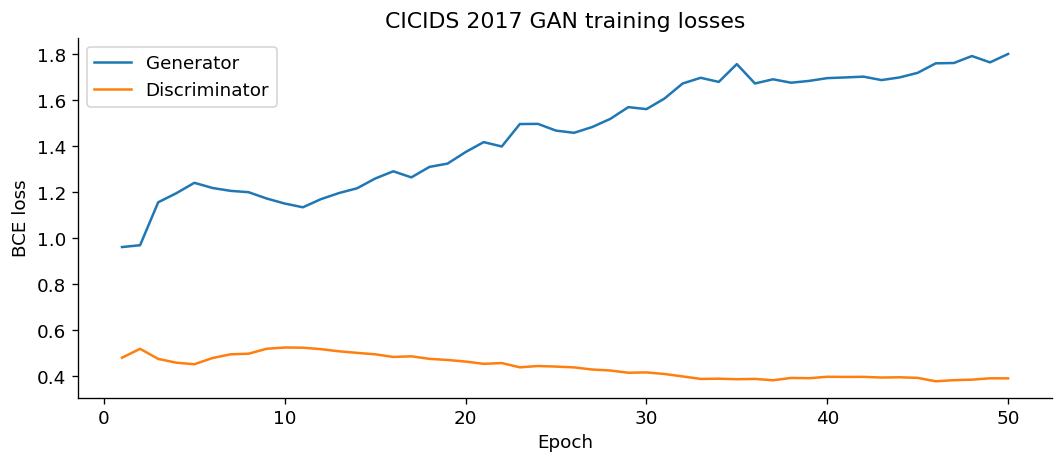

In [14]:
LATENT_DIM = 64
BATCH_SIZE = 256
EPOCHS = 50
LEARNING_RATE = 0.0002

class TrafficGenerator(nn.Module):
    """Convert random noise into scaled numerical traffic features."""
    def __init__(self, output_features):
        super().__init__()
        self.network = nn.Sequential(
            nn.Linear(LATENT_DIM, 128),
            nn.LeakyReLU(0.2),
            nn.Linear(128, 256),
            nn.LeakyReLU(0.2),
            nn.Linear(256, 256),
            nn.LeakyReLU(0.2),
            nn.Linear(256, output_features),
            nn.Tanh()
        )

    def forward(self, noise):
        return self.network(noise)


class TrafficDiscriminator(nn.Module):
    """Return a real-versus-generated logit for a traffic record."""
    def __init__(self, input_features):
        super().__init__()
        self.network = nn.Sequential(
            nn.Linear(input_features, 256),
            nn.LeakyReLU(0.2),
            nn.Linear(256, 128),
            nn.LeakyReLU(0.2),
            nn.Linear(128, 1)
        )

    def forward(self, records):
        return self.network(records).flatten()


def initialise_weights(module):
    """Initialise fully connected layers consistently."""
    if isinstance(module, nn.Linear):
        nn.init.xavier_uniform_(module.weight)
        nn.init.zeros_(module.bias)


def train_traffic_gan(generator, discriminator, loader, epochs):
    """Train the GAN and return sample-weighted epoch losses."""
    criterion = nn.BCEWithLogitsLoss()

    g_optimizer = torch.optim.Adam(
        generator.parameters(), lr=LEARNING_RATE, betas=(0.5, 0.999)
    )
    d_optimizer = torch.optim.Adam(
        discriminator.parameters(), lr=LEARNING_RATE, betas=(0.5, 0.999)
    )

    history = []

    for epoch in range(1, epochs + 1):
        generator.train()
        discriminator.train()
        g_total, d_total, count = 0.0, 0.0, 0

        for (real_records,) in loader:
            real_records = real_records.to(device)
            size = real_records.size(0)

            real_targets = torch.ones(size, device=device)
            fake_targets = torch.zeros(size, device=device)

            # I update the discriminator using real and detached fake records.
            d_optimizer.zero_grad(set_to_none=True)

            noise = torch.randn(size, LATENT_DIM, device=device)
            fake_records = generator(noise)

            d_loss = 0.5 * (
                criterion(discriminator(real_records), real_targets)
                + criterion(discriminator(fake_records.detach()), fake_targets)
            )
            d_loss.backward()
            d_optimizer.step()

            # I update the generator while keeping discriminator weights fixed.
            for parameter in discriminator.parameters():
                parameter.requires_grad_(False)

            g_optimizer.zero_grad(set_to_none=True)
            noise = torch.randn(size, LATENT_DIM, device=device)
            generated_records = generator(noise)

            g_loss = criterion(
                discriminator(generated_records), real_targets
            )
            g_loss.backward()
            g_optimizer.step()

            for parameter in discriminator.parameters():
                parameter.requires_grad_(True)

            g_total += g_loss.item() * size
            d_total += d_loss.item() * size
            count += size

        history.append({
            "epoch": epoch,
            "generator_loss": g_total / count,
            "discriminator_loss": d_total / count
        })

        if epoch == 1 or epoch % 5 == 0:
            print(
                f"Epoch {epoch:02d}/{epochs} | "
                f"G: {g_total / count:.4f} | "
                f"D: {d_total / count:.4f}"
            )

    return pd.DataFrame(history)


set_seed()

train_loader = DataLoader(
    TensorDataset(torch.from_numpy(X_train)),
    batch_size=BATCH_SIZE,
    shuffle=True,
    generator=torch.Generator().manual_seed(SEED)
)

generator = TrafficGenerator(N_FEATURES).to(device)
discriminator = TrafficDiscriminator(N_FEATURES).to(device)

generator.apply(initialise_weights)
discriminator.apply(initialise_weights)

history = train_traffic_gan(
    generator, discriminator, train_loader, EPOCHS
)

plt.figure(figsize=(9, 4))
plt.plot(history["epoch"], history["generator_loss"], label="Generator")
plt.plot(history["epoch"], history["discriminator_loss"], label="Discriminator")
plt.title("CICIDS 2017 GAN training losses")
plt.xlabel("Epoch")
plt.ylabel("BCE loss")
plt.legend()
plt.tight_layout()
plt.show()

Generated traffic shape: (10000, 68)


,Destination Port,Flow Duration,Total Fwd Packets,Total Backward Packets,Total Length of Fwd Packets,Total Length of Bwd Packets,Fwd Packet Length Max,Fwd Packet Length Min,Fwd Packet Length Mean,Fwd Packet Length Std,...,act_data_pkt_fwd,min_seg_size_forward,Active Mean,Active Std,Active Max,Active Min,Idle Mean,Idle Std,Idle Max,Idle Min
0,53.000000,6.081403e+03,2.0,2.0,94.000000,229.791992,47.000000,47.0,48.000000,0.000000,...,1.0,32.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,53.000000,3.045604e+04,1.0,1.0,0.000000,0.000000,0.000000,0.0,0.000000,0.000000,...,0.0,32.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,443.000000,1.137605e+07,8.0,14.0,719.537048,11595.000000,365.114563,0.0,74.186821,157.472961,...,3.0,32.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,53.000000,1.947177e+02,2.0,2.0,72.000000,331.754974,34.000000,34.0,35.000000,0.000000,...,1.0,20.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,39894.441406,2.942925e+04,13.0,8.0,380.784058,9429.047852,277.901581,0.0,41.314552,7.388829,...,5.0,32.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


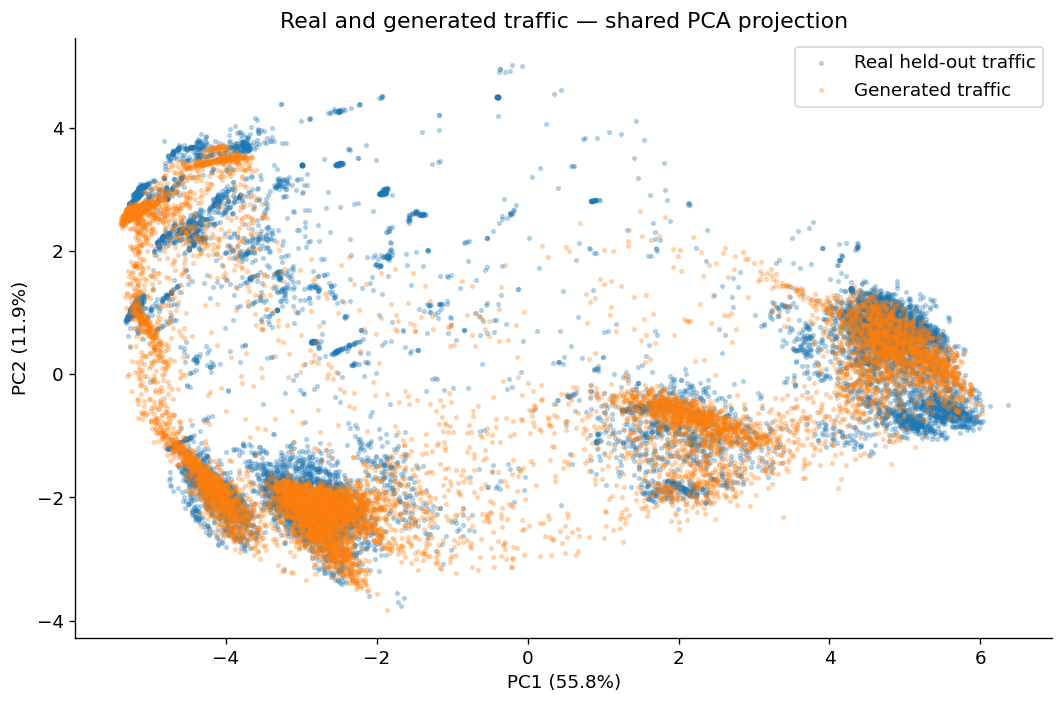

/usr/local/lib/python3.13/dist-packages/scipy/stats/_axis_nan_policy.py:579: RuntimeWarning: ks_2samp: Exact calculation unsuccessful. Switching to method=asymp.
  res = hypotest_fun_out(*samples, **kwds)



Per-feature distribution comparison:


,Feature,KS statistic,Normalised Wasserstein
34,Bwd Packets/s,0.2658,0.0606
67,Idle Min,0.2249,0.4167
64,Idle Mean,0.2037,0.3782
66,Idle Max,0.1966,0.3960
16,Flow IAT Mean,0.1914,0.2681
...,...,...,...
43,PSH Flag Count,0.0236,0.0567
59,min_seg_size_forward,0.0197,0.0560
45,URG Flag Count,0.0096,0.0367
46,ECE Flag Count,0.0004,0.0210


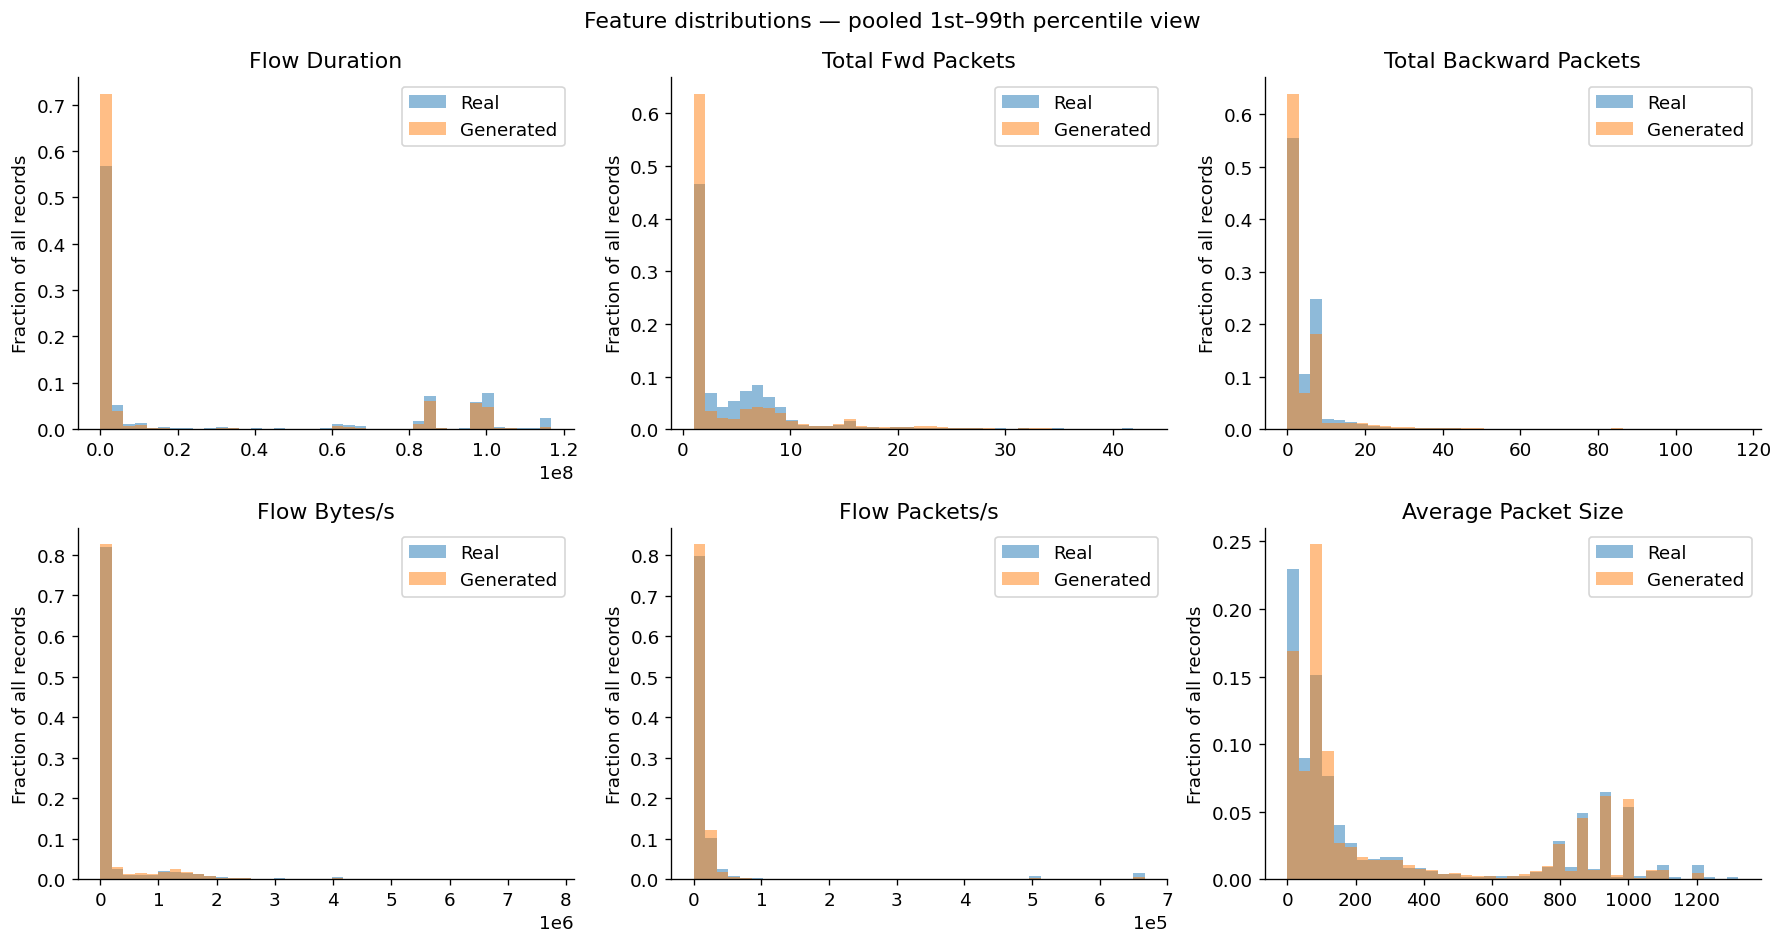

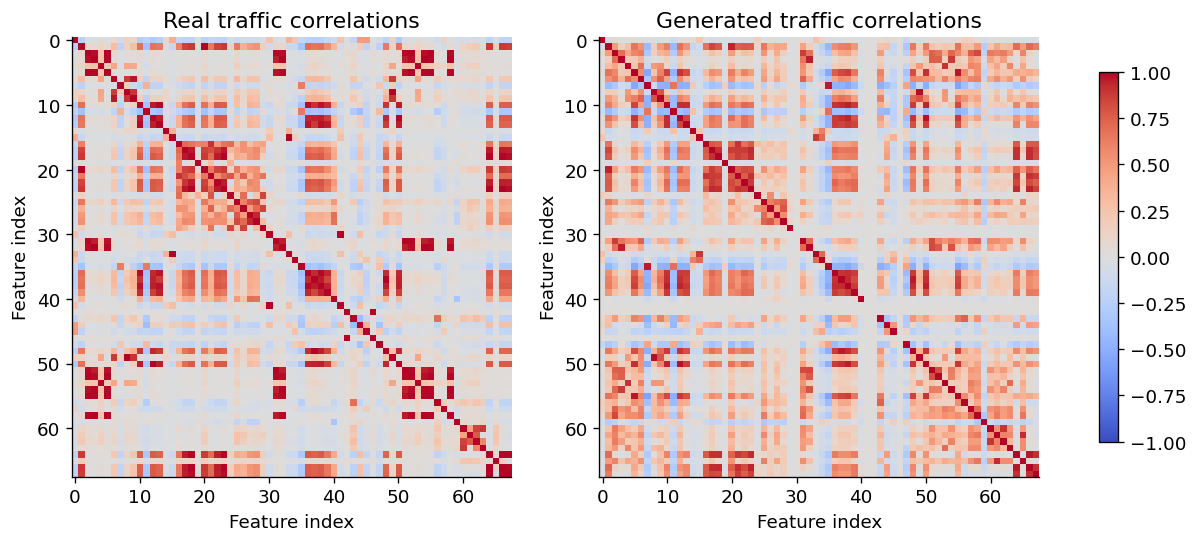


Overall quantitative evaluation:


,Real evaluation records,Generated records,Features,Mean KS statistic,Mean normalised Wasserstein,Off-diagonal correlation MAE,Negative values in nonnegative features (%),Fractional values in integer-like features (%),Non-finite generated values (%)
0,10000,10000,68,0.1161,0.1992,0.1438,0.0,16.7314,0.0


In [15]:
@torch.no_grad()
def generate_traffic(model, n_samples, batch_size=512):
    """Generate a reproducible collection of scaled traffic records."""
    previous_mode = model.training
    model.eval()
    noise_rng = torch.Generator().manual_seed(SEED + 100)
    batches = []

    for start in range(0, n_samples, batch_size):
        size = min(batch_size, n_samples - start)
        noise = torch.randn(
            size, LATENT_DIM, generator=noise_rng
        ).to(device)
        batches.append(model(noise).cpu().numpy())

    model.train(previous_mode)
    return np.concatenate(batches)


N_EVAL = min(10000, len(X_test))
rng = np.random.default_rng(SEED)
evaluation_indices = rng.choice(len(X_test), N_EVAL, replace=False)

real_scaled = X_test[evaluation_indices]
real_original = test_imputed[evaluation_indices]
fake_scaled = generate_traffic(generator, N_EVAL)

# I restore original units without rounding or correcting generated values.
fake_original = transformer.inverse_transform(
    np.clip((fake_scaled + 1) / 2, 0, 1)
)

synthetic_traffic = pd.DataFrame(
    fake_original, columns=feature_names
)

print("Generated traffic shape:", synthetic_traffic.shape)
display(synthetic_traffic.head())

# I fit PCA once on real training data and project both evaluation datasets.
pca = PCA(n_components=2, random_state=SEED)
pca.fit(X_train)

real_pca = pca.transform(real_scaled)
fake_pca = pca.transform(fake_scaled)

plt.figure(figsize=(9, 6))
plt.scatter(
    real_pca[:, 0], real_pca[:, 1],
    s=5, alpha=0.25, label="Real held-out traffic"
)
plt.scatter(
    fake_pca[:, 0], fake_pca[:, 1],
    s=5, alpha=0.25, label="Generated traffic"
)
plt.xlabel(f"PC1 ({100 * pca.explained_variance_ratio_[0]:.1f}%)")
plt.ylabel(f"PC2 ({100 * pca.explained_variance_ratio_[1]:.1f}%)")
plt.title("Real and generated traffic — shared PCA projection")
plt.legend()
plt.tight_layout()
plt.show()

# I compare marginal distributions in original units.
training_scales = np.std(train_imputed, axis=0)
training_scales = np.where(training_scales > 0, training_scales, 1)

metric_rows = []

for j, feature in enumerate(feature_names):
    metric_rows.append({
        "Feature": feature,
        "KS statistic": ks_2samp(
            real_original[:, j], fake_original[:, j]
        ).statistic,
        "Normalised Wasserstein": wasserstein_distance(
            real_original[:, j], fake_original[:, j]
        ) / training_scales[j]
    })

feature_metrics = pd.DataFrame(metric_rows)

print("\nPer-feature distribution comparison:")
display(
    feature_metrics.sort_values(
        "KS statistic", ascending=False
    ).round(4)
)

# I use the same feature selection for the real and generated histograms.
preferred = [
    "Flow Duration", "Total Fwd Packets", "Total Backward Packets",
    "Flow Bytes/s", "Flow Packets/s", "Average Packet Size"
]
plot_features = [c for c in preferred if c in feature_names]

for feature in feature_names:
    if len(plot_features) >= 6:
        break
    if feature not in plot_features:
        plot_features.append(feature)

fig, axes = plt.subplots(2, 3, figsize=(15, 8))

for ax, feature in zip(axes.ravel(), plot_features):
    j = feature_names.index(feature)
    real_values = real_original[:, j]
    fake_values = fake_original[:, j]

    # I use pooled 1st–99th percentile limits to show the central distributions.
    lower, upper = np.quantile(
        np.concatenate([real_values, fake_values]), [0.01, 0.99]
    )
    if upper <= lower:
        upper = lower + 1

    bins = np.linspace(lower, upper, 40)

    ax.hist(
        real_values, bins=bins, alpha=0.5,
        weights=np.ones(N_EVAL) / N_EVAL, label="Real"
    )
    ax.hist(
        fake_values, bins=bins, alpha=0.5,
        weights=np.ones(N_EVAL) / N_EVAL, label="Generated"
    )
    ax.set_title(feature)
    ax.set_ylabel("Fraction of all records")
    ax.ticklabel_format(axis="x", style="sci", scilimits=(-3, 4))
    ax.legend()

for ax in axes.ravel()[len(plot_features):]:
    ax.axis("off")

fig.suptitle("Feature distributions — pooled 1st–99th percentile view")
plt.tight_layout()
plt.show()

# I compare dependencies; zero-variance correlations are represented as zero.
def correlation_matrix(values):
    return (
        pd.DataFrame(values)
        .corr()
        .fillna(0)
        .to_numpy()
    )

real_corr = correlation_matrix(real_original)
fake_corr = correlation_matrix(fake_original)

off_diagonal = ~np.eye(N_FEATURES, dtype=bool)
correlation_error = np.abs(
    real_corr - fake_corr
)[off_diagonal].mean()

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for ax, matrix, title in [
    (axes[0], real_corr, "Real traffic correlations"),
    (axes[1], fake_corr, "Generated traffic correlations")
]:
    image = ax.imshow(matrix, vmin=-1, vmax=1, cmap="coolwarm")
    ax.set_title(title)
    ax.set_xlabel("Feature index")
    ax.set_ylabel("Feature index")

fig.colorbar(image, ax=axes.ravel().tolist(), shrink=0.8)
plt.show()

negative_rate = (
    100 * (fake_original[:, nonnegative_features] < -1e-6).mean()
    if nonnegative_features.any() else np.nan
)

fractional_rate = (
    100 * (
        np.abs(
            fake_original[:, integer_features]
            - np.round(fake_original[:, integer_features])
        ) > 1e-3
    ).mean()
    if integer_features.any() else np.nan
)

summary = pd.DataFrame([{
    "Real evaluation records": N_EVAL,
    "Generated records": N_EVAL,
    "Features": N_FEATURES,
    "Mean KS statistic": feature_metrics["KS statistic"].mean(),
    "Mean normalised Wasserstein":
        feature_metrics["Normalised Wasserstein"].mean(),
    "Off-diagonal correlation MAE": correlation_error,
    "Negative values in nonnegative features (%)": negative_rate,
    "Fractional values in integer-like features (%)": fractional_rate,
    "Non-finite generated values (%)":
        100 * (~np.isfinite(fake_original)).mean()
}])

print("\nOverall quantitative evaluation:")
display(summary.round(4))

Device: cuda
Category: birthday cake
Downloaded sketches: 144982
Image dimensions: (28, 28)
Data type: uint8
Pixel range: (np.uint8(0), np.uint8(255))
Exact duplicates removed: 4
Unique sketches: 144978


,Split,Sketches
0,Training,48000
1,Validation,6000
2,Test,6000


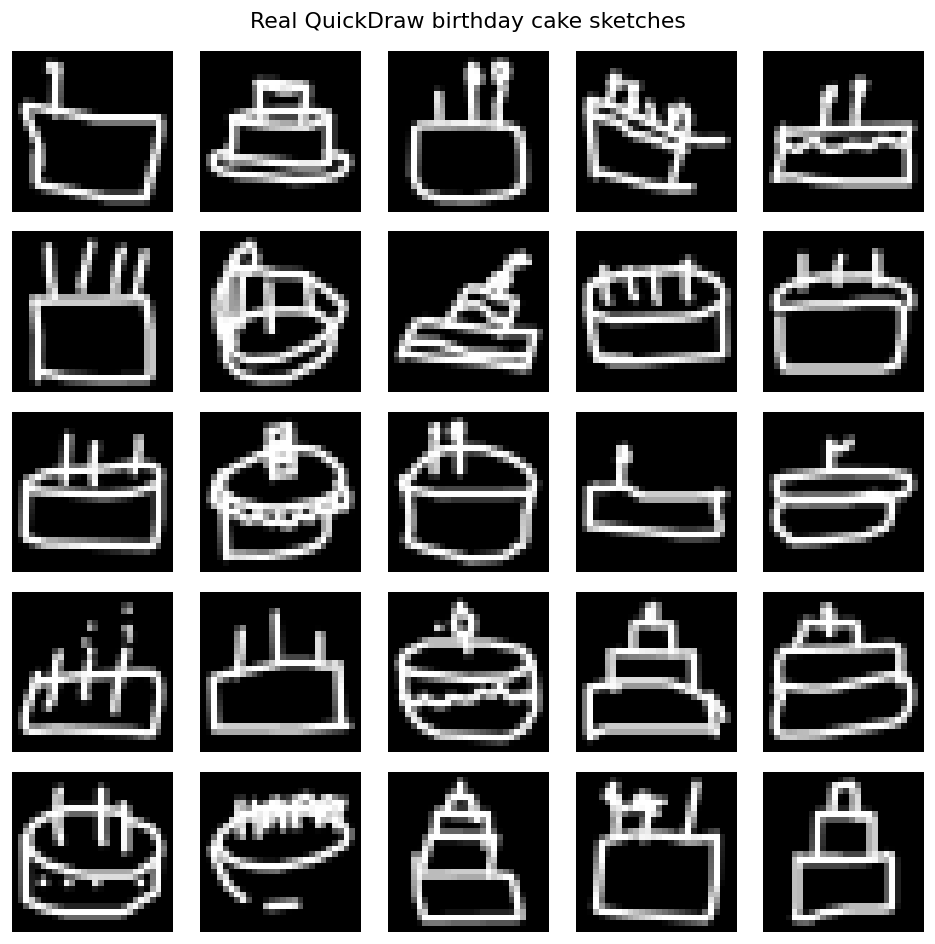

Model input shape: (1, 64, 64)


In [16]:
%pip -q install torchmetrics torch-fidelity

import random
import urllib.request
from urllib.parse import quote

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from torchvision.utils import make_grid
from torchmetrics.image.fid import FrechetInceptionDistance

SEED = 42
LATENT_DIM = 100
BATCH_SIZE = 128

def set_seed(seed=SEED):
    """Set random seeds for repeatable sampling and training."""
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False


set_seed()
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

# I download the birthday cake category from the public QuickDraw dataset.
category = "birthday cake"
url = (
    "https://storage.googleapis.com/quickdraw_dataset/"
    f"full/numpy_bitmap/{quote(category, safe='')}.npy"
)
data_path = "/content/birthday_cake.npy"

urllib.request.urlretrieve(url, data_path)
raw_images = np.load(data_path, allow_pickle=False).reshape(-1, 28, 28)

print("Category:", category)
print("Downloaded sketches:", len(raw_images))
print("Image dimensions:", raw_images.shape[1:])
print("Data type:", raw_images.dtype)
print("Pixel range:", (raw_images.min(), raw_images.max()))

# I remove exact duplicate images before creating separate data subsets.
flat_images = raw_images.reshape(len(raw_images), -1)
_, unique_indices = np.unique(
    flat_images, axis=0, return_index=True
)
images = raw_images[np.sort(unique_indices)]

print("Exact duplicates removed:", len(raw_images) - len(images))
print("Unique sketches:", len(images))

# I use a reproducible subset to keep training manageable in Colab.
MAX_IMAGES = 60000
rng = np.random.default_rng(SEED)
selected_indices = rng.permutation(len(images))[:MAX_IMAGES]
images = images[selected_indices]

n_train = int(0.8 * len(images))
n_val = int(0.1 * len(images))

train_images = images[:n_train]
val_images = images[n_train:n_train + n_val]
test_images = images[n_train + n_val:]

display(pd.DataFrame({
    "Split": ["Training", "Validation", "Test"],
    "Sketches": [
        len(train_images), len(val_images), len(test_images)
    ]
}))

# I display sketches from the training subset.
example_indices = rng.choice(len(train_images), 25, replace=False)

fig, axes = plt.subplots(5, 5, figsize=(8, 8))
for ax, index in zip(axes.ravel(), example_indices):
    ax.imshow(
        train_images[index], cmap="gray", vmin=0, vmax=255
    )
    ax.axis("off")

fig.suptitle("Real QuickDraw birthday cake sketches")
plt.tight_layout()
plt.show()

transform = transforms.Compose([
    transforms.ToPILImage(),
    transforms.Resize((64, 64)),
    transforms.ToTensor(),
    transforms.Normalize((0.5,), (0.5,))
])

class SketchDataset(Dataset):
    """Transform grayscale sketches into normalised 64 × 64 tensors."""

    def __init__(self, images, transform):
        self.images = images
        self.transform = transform

    def __len__(self):
        return len(self.images)

    def __getitem__(self, index):
        return self.transform(self.images[index])


train_dataset = SketchDataset(train_images, transform)
test_dataset = SketchDataset(test_images, transform)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    drop_last=True,
    num_workers=2,
    pin_memory=(device.type == "cuda"),
    generator=torch.Generator().manual_seed(SEED)
)

print("Model input shape:", tuple(train_dataset[0].shape))

Epoch 01/30 | G: 0.1171 | D: 0.0048
Epoch 02/30 | G: 0.0005 | D: 0.0000
Epoch 03/30 | G: 0.0002 | D: 0.0000
Epoch 04/30 | G: 0.0001 | D: 0.0000
Epoch 05/30 | G: 0.0001 | D: 0.0000
Epoch 06/30 | G: 0.0001 | D: 0.0000
Epoch 07/30 | G: 0.0000 | D: 0.0000
Epoch 08/30 | G: 0.0000 | D: 0.0000
Epoch 09/30 | G: 0.0000 | D: 0.0000
Epoch 10/30 | G: 0.0000 | D: 0.0000
Epoch 11/30 | G: 0.0000 | D: 0.0000
Epoch 12/30 | G: 0.0000 | D: 0.0000
Epoch 13/30 | G: 0.0000 | D: 0.0000
Epoch 14/30 | G: 0.0000 | D: 0.0000
Epoch 15/30 | G: 0.0000 | D: 0.0000
Epoch 16/30 | G: 0.0000 | D: 0.0000
Epoch 17/30 | G: 0.0000 | D: 0.0000
Epoch 18/30 | G: 0.0000 | D: 0.0000
Epoch 19/30 | G: 0.0000 | D: 0.0000
Epoch 20/30 | G: 0.0000 | D: 0.0000
Epoch 21/30 | G: 0.0000 | D: 0.0000
Epoch 22/30 | G: 0.0000 | D: 0.0000
Epoch 23/30 | G: 0.0000 | D: 0.0000
Epoch 24/30 | G: 0.0000 | D: 0.0000
Epoch 25/30 | G: 0.0000 | D: 0.0000
Epoch 26/30 | G: 0.0000 | D: 0.0000
Epoch 27/30 | G: 0.0000 | D: 0.0000
Epoch 28/30 | G: 0.0000 | D:

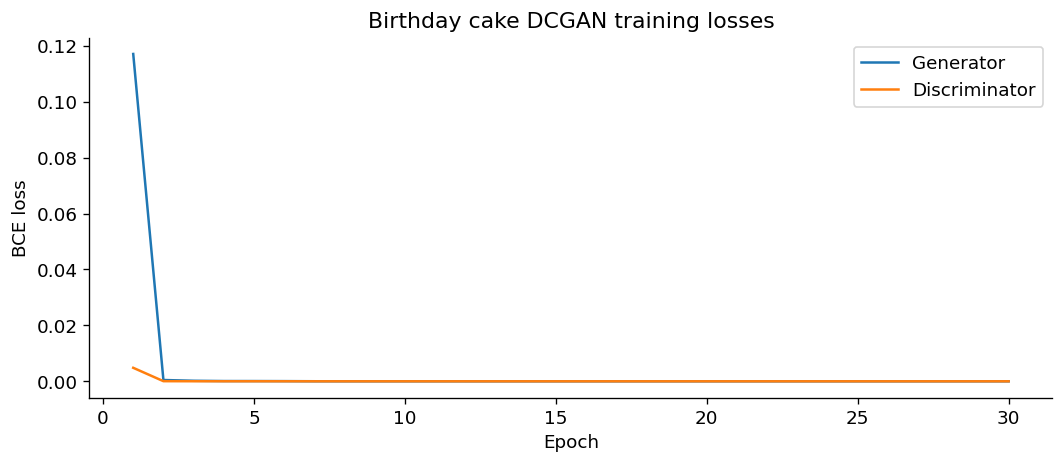

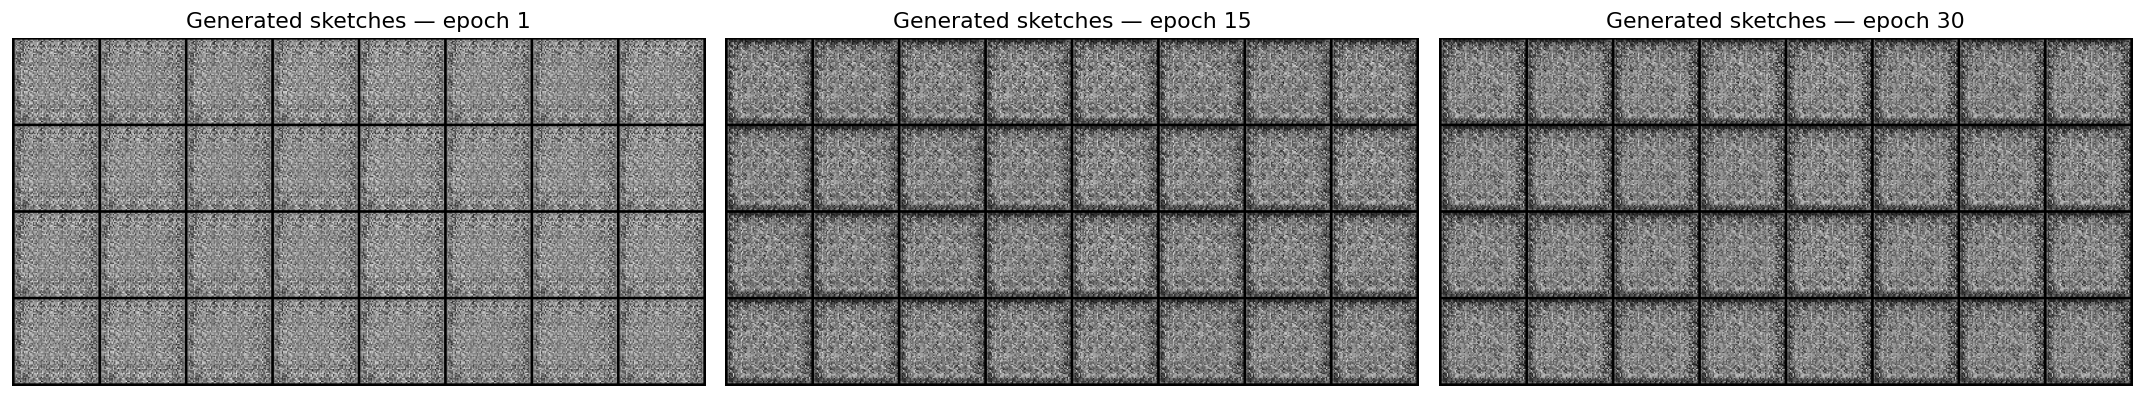

In [18]:
EPOCHS = 30
LEARNING_RATE = 0.0002
BASE = 32

class CakeGenerator(nn.Module):
    """Generate grayscale 64 × 64 sketches from latent noise."""

    def __init__(self):
        super().__init__()

        self.network = nn.Sequential(
            nn.ConvTranspose2d(LATENT_DIM, BASE * 8, 4, 1, 0, bias=False),
            nn.BatchNorm2d(BASE * 8),
            nn.ReLU(True),

            nn.ConvTranspose2d(BASE * 8, BASE * 4, 4, 2, 1, bias=False),
            nn.BatchNorm2d(BASE * 4),
            nn.ReLU(True),

            nn.ConvTranspose2d(BASE * 4, BASE * 2, 4, 2, 1, bias=False),
            nn.BatchNorm2d(BASE * 2),
            nn.ReLU(True),

            nn.ConvTranspose2d(BASE * 2, BASE, 4, 2, 1, bias=False),
            nn.BatchNorm2d(BASE),
            nn.ReLU(True),

            nn.ConvTranspose2d(BASE, 1, 4, 2, 1, bias=False),
            nn.Tanh()
        )

    def forward(self, noise):
        return self.network(noise)


class CakeDiscriminator(nn.Module):
    """Return a real-versus-generated logit for each sketch."""

    def __init__(self):
        super().__init__()

        self.network = nn.Sequential(
            nn.Conv2d(1, BASE, 4, 2, 1, bias=False),
            nn.LeakyReLU(0.2, inplace=True),

            nn.Conv2d(BASE, BASE * 2, 4, 2, 1, bias=False),
            nn.BatchNorm2d(BASE * 2),
            nn.LeakyReLU(0.2, inplace=True),

            nn.Conv2d(BASE * 2, BASE * 4, 4, 2, 1, bias=False),
            nn.BatchNorm2d(BASE * 4),
            nn.LeakyReLU(0.2, inplace=True),

            nn.Conv2d(BASE * 4, BASE * 8, 4, 2, 1, bias=False),
            nn.BatchNorm2d(BASE * 8),
            nn.LeakyReLU(0.2, inplace=True),

            nn.Conv2d(BASE * 8, 1, 4, 1, 0, bias=False)
        )

    def forward(self, sketches):
        return self.network(sketches).flatten()


def initialise_weights(module):
    """Apply conventional DCGAN weight initialisation."""
    if isinstance(module, (nn.Conv2d, nn.ConvTranspose2d)):
        nn.init.normal_(module.weight, 0.0, 0.02)

    elif isinstance(module, nn.BatchNorm2d):
        nn.init.normal_(module.weight, 1.0, 0.02)
        nn.init.zeros_(module.bias)


@torch.no_grad()
def generate_sketches(model, noise):
    """Generate sketches without changing batch-normalisation statistics."""
    previous_mode = model.training
    model.eval()
    generated = model(noise).cpu()
    model.train(previous_mode)
    return generated


def train_dcgan(generator, discriminator, loader, epochs):
    """Train the GAN and collect losses and fixed-noise sample grids."""
    criterion = nn.BCEWithLogitsLoss()

    g_optimizer = torch.optim.Adam(
        generator.parameters(),
        lr=LEARNING_RATE,
        betas=(0.5, 0.999)
    )
    d_optimizer = torch.optim.Adam(
        discriminator.parameters(),
        lr=LEARNING_RATE,
        betas=(0.5, 0.999)
    )

    fixed_noise = torch.randn(32, LATENT_DIM, 1, 1, device=device)
    snapshot_epochs = {1, max(1, epochs // 2), epochs}
    history, snapshots = [], {}

    for epoch in range(1, epochs + 1):
        generator.train()
        discriminator.train()

        g_total, d_total, count = 0.0, 0.0, 0

        for real_sketches in loader:
            real_sketches = real_sketches.to(device, non_blocking=True)
            size = real_sketches.size(0)

            real_targets = torch.ones(size, device=device)
            fake_targets = torch.zeros(size, device=device)

            # I train the discriminator using real and detached fake sketches.
            d_optimizer.zero_grad(set_to_none=True)

            noise = torch.randn(size, LATENT_DIM, 1, 1, device=device)
            fake_sketches = generator(noise)

            d_loss = 0.5 * (
                criterion(discriminator(real_sketches), real_targets)
                + criterion(
                    discriminator(fake_sketches.detach()), fake_targets
                )
            )

            d_loss.backward()
            d_optimizer.step()

            # I freeze discriminator weights during the generator update.
            discriminator.eval()
            for parameter in discriminator.parameters():
                parameter.requires_grad_(False)

            g_optimizer.zero_grad(set_to_none=True)

            g_loss = criterion(
                discriminator(fake_sketches), real_targets
            )
            g_loss.backward()
            g_optimizer.step()

            for parameter in discriminator.parameters():
                parameter.requires_grad_(True)
            discriminator.train()

            g_total += g_loss.item() * size
            d_total += d_loss.item() * size
            count += size

        history.append({
            "epoch": epoch,
            "generator_loss": g_total / count,
            "discriminator_loss": d_total / count
        })

        if epoch in snapshot_epochs:
            snapshots[epoch] = generate_sketches(generator, fixed_noise)

        print(
            f"Epoch {epoch:02d}/{epochs} | "
            f"G: {g_total / count:.4f} | "
            f"D: {d_total / count:.4f}"
        )

    return pd.DataFrame(history), snapshots


set_seed()

generator = CakeGenerator().to(device)
discriminator = CakeDiscriminator().to(device)

generator.apply(initialise_weights)
discriminator.apply(initialise_weights)

history, snapshots = train_dcgan(
    generator, discriminator, train_loader, EPOCHS
)

plt.figure(figsize=(9, 4))
plt.plot(history["epoch"], history["generator_loss"], label="Generator")
plt.plot(history["epoch"], history["discriminator_loss"], label="Discriminator")
plt.title("Birthday cake DCGAN training losses")
plt.xlabel("Epoch")
plt.ylabel("BCE loss")
plt.legend()
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(
    1, len(snapshots),
    figsize=(6 * len(snapshots), 5),
    squeeze=False
)

for ax, (epoch, sketches) in zip(axes.ravel(), snapshots.items()):
    grid = make_grid(
        ((sketches + 1) / 2).clamp(0, 1),
        nrow=8,
        padding=2
    )
    ax.imshow(grid.permute(1, 2, 0).numpy())
    ax.set_title(f"Generated sketches — epoch {epoch}")
    ax.axis("off")

plt.tight_layout()
plt.show()

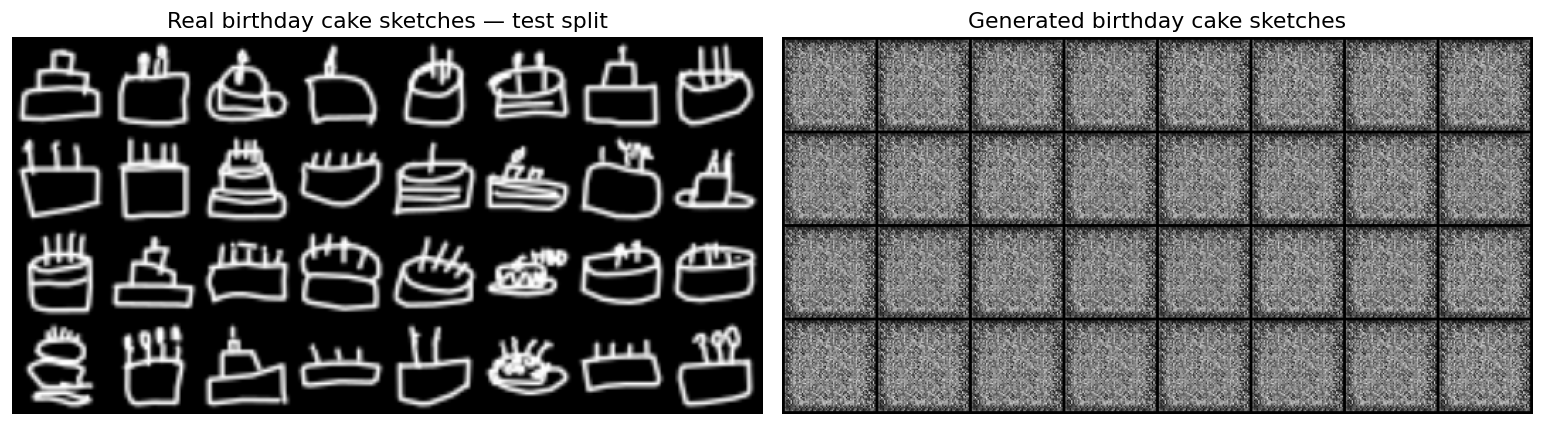

Calculating FID; Inception weights may download on the first run.


,Dataset,Model,Training images,Epochs,Image dimensions,Real evaluation images,Generated evaluation images,FID feature dimensions,FID
0,QuickDraw birthday cake,DCGAN,48000,30,64 × 64,2000,2000,2048,386.0527


In [19]:
N_EVAL = min(2000, len(test_dataset))
EVAL_BATCH_SIZE = 64

rng = np.random.default_rng(SEED)
test_indices = rng.choice(
    len(test_dataset), N_EVAL, replace=False
)

evaluation_loader = DataLoader(
    torch.utils.data.Subset(test_dataset, test_indices.tolist()),
    batch_size=EVAL_BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=(device.type == "cuda")
)

real_examples = torch.stack([
    test_dataset[int(index)] for index in test_indices[:32]
])

noise_rng = torch.Generator().manual_seed(SEED + 100)
example_noise = torch.randn(
    32, LATENT_DIM, 1, 1, generator=noise_rng
).to(device)

fake_examples = generate_sketches(generator, example_noise)

fig, axes = plt.subplots(1, 2, figsize=(13, 6))

for ax, sketches, title in [
    (axes[0], real_examples, "Real birthday cake sketches — test split"),
    (axes[1], fake_examples, "Generated birthday cake sketches")
]:
    grid = make_grid(
        ((sketches + 1) / 2).clamp(0, 1),
        nrow=8,
        padding=2
    )

    ax.imshow(grid.permute(1, 2, 0).numpy())
    ax.set_title(title)
    ax.axis("off")

plt.tight_layout()
plt.show()


def prepare_for_fid(sketches):
    """Convert normalised grayscale sketches to three-channel [0, 1] images."""
    return ((sketches + 1) / 2).clamp(0, 1).repeat(1, 3, 1, 1)


@torch.no_grad()
def calculate_fid(model, loader):
    """Calculate Inception FID using equal real and generated sample counts."""
    metric = FrechetInceptionDistance(
        feature=2048,
        normalize=True
    ).to(device)

    metric.set_dtype(torch.float64)

    previous_mode = model.training
    model.eval()

    noise_rng = torch.Generator().manual_seed(SEED + 200)
    total = 0

    for real_sketches in loader:
        real_sketches = real_sketches.to(device, non_blocking=True)
        size = real_sketches.size(0)

        noise = torch.randn(
            size, LATENT_DIM, 1, 1, generator=noise_rng
        ).to(device)

        fake_sketches = model(noise)

        metric.update(prepare_for_fid(real_sketches), real=True)
        metric.update(prepare_for_fid(fake_sketches), real=False)

        total += size

    score = float(metric.compute().cpu())
    model.train(previous_mode)

    return score, total


print("Calculating FID; Inception weights may download on the first run.")
fid_score, evaluated_count = calculate_fid(
    generator, evaluation_loader
)

results = pd.DataFrame([{
    "Dataset": "QuickDraw birthday cake",
    "Model": "DCGAN",
    "Training images": len(train_dataset),
    "Epochs": EPOCHS,
    "Image dimensions": "64 × 64",
    "Real evaluation images": evaluated_count,
    "Generated evaluation images": evaluated_count,
    "FID feature dimensions": 2048,
    "FID": fid_score
}])

display(results.round(4))